<a href="https://colab.research.google.com/github/imguru-mooc/AI_CAMPUS/blob/main/VB-day3/VB_Day3_lecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Vision 기본 모델 Day 3 — 경량 CNN · 전이학습 · Grad-CAM

**온디바이스 AI · Vision 기본 모델 3/5 · 10/29(목)** · Google Colab (GPU 런타임) · PyTorch · CIFAR-10

오늘의 목표

1. 같은 문제를 푸는 모델들의 **정확도 · 파라미터 · 연산량(MAC) · 지연시간**을 함께 재고, 온디바이스에 맞는 모델을 고르는 기준을 세운다.
2. **Depthwise Separable Convolution** 이 연산량을 약 1/8~1/9 로 줄이는 원리를 공식과 코드로 확인한다.
3. MobileNet V1 → V2 (inverted residual) → V3 (SE · h-swish) 로 이어지는 경량화 설계를 직접 구현하며 따라간다.
4. ImageNet 으로 학습된 MobileNetV3 를 가져와 **전이학습** (feature extraction · fine-tuning) 하고, 데이터가 적을수록 효과가 커지는 것을 실험으로 본다.
5. **Grad-CAM** 으로 모델이 이미지의 어디를 보고 판단했는지 확인한다.
6. 8교시 미니 프로젝트에서 **MobileNetV3 전이학습 모델**과 Day 2 의 **ResNet-20** 을 정확도 · 연산량 · 지연시간으로 비교한다.

| 교시 | 시간 | 주제 |
|---|---|---|
| 1 | 09:00–09:50 | Day 2 복습 퀴즈 · 정확도 vs 속도 |
| 2 | 10:00–10:50 | 연산량 계산 — 파라미터 · MAC · 메모리 · 1×1 bottleneck |
| 3 | 11:00–11:50 | Depthwise Separable Convolution |
| 4 | 13:00–13:50 | MobileNet V1 · V2 · V3 |
| 5 | 14:00–14:50 | 전이학습 — feature extraction vs fine-tuning |
| 6 | 15:00–15:50 | 적은 데이터와 전이학습 |
| 7 | 16:00–16:50 | Grad-CAM — 모델은 어디를 보는가 |
| 8 | 17:00–17:50 | 미니 프로젝트 — MobileNetV3 전이학습 vs ResNet-20 (이 노트북 맨 끝) |

**노트북 사용법**

1. *런타임 → 런타임 유형 변경 → T4 GPU* 를 고르고, *파일 → Drive에 사본 저장* 후 사본에서 작업합니다.
2. `____` 가 있는 셀은 빈칸을 채운 뒤 실행하고, 아래 **확인 셀**이 `✅` 를 출력하면 정답입니다.
3. 막히면 **🔒 정답 보기** 셀을 실행하세요. 🖼 그림 셀은 실행하지 않아도 그림이 보입니다.
4. 8교시 미니 프로젝트는 이 노트북 맨 끝에 있습니다. 채점 셀 결과가 보이는 상태로 제출합니다.

### 📚 오늘의 온라인 자료

| 자료 | 링크 |
|---|---|
| 🎬 애니메이션 (시뮬레이션 8개) | [https://imguru-mooc.github.io/AI_CAMPUS/VB-day3/animation.html](https://imguru-mooc.github.io/AI_CAMPUS/VB-day3/animation.html) |
| 📝 개념 워크시트 (8교시 × 10문항) | [https://imguru-mooc.github.io/AI_CAMPUS/VB-day3/worksheet.html](https://imguru-mooc.github.io/AI_CAMPUS/VB-day3/worksheet.html) |
| 🖥 슬라이드 (PDF) | [https://imguru-mooc.github.io/AI_CAMPUS/VB-day3/VB_Day3.pdf](https://imguru-mooc.github.io/AI_CAMPUS/VB-day3/VB_Day3.pdf) |

오늘은 원래 '현장 안전 이미지' 로 하려던 전이학습을 **Day 2 와 같은 CIFAR-10** 으로 합니다. 같은 데이터에서 '처음부터 학습한 ResNet-20' 과 '사전학습 모델을 가져온 MobileNetV3' 를 공정하게 비교할 수 있습니다. 코드는 `ImageFolder` 데이터로 그대로 바꿔 쓸 수 있습니다 (6교시).

In [ ]:
# ▶ 환경 셀 — 런타임이 끊기면 이 셀부터 다시 실행하세요
import os, time, copy, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import datasets, transforms

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (5, 4)
torch.manual_seed(0)
rng = np.random.default_rng(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
NW = 2 if device.type == "cuda" else 0
RAW_D2 = "https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day2"
CLASSES = ("airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")
CIFAR_MEAN, CIFAR_STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
IMNET_MEAN, IMNET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)     # ImageNet 사전학습 모델의 정규화
IMG = 96                                       # MobileNet 입력 크기 (32 → 96 으로 키워서 넣는다)
W_MNV3S = torchvision.models.MobileNet_V3_Small_Weights.IMAGENET1K_V1   # ImageNet 사전학습 가중치

# ── Day 2 에서 만든 함수 · 모델 ────────────────────────────────
def count_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)

def train_one_epoch(model, loader, loss_fn, opt, scheduler=None):
    model.train()
    total, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        logits = model(xb)
        loss = loss_fn(logits, yb)
        opt.zero_grad(); loss.backward(); opt.step()
        if scheduler is not None:
            scheduler.step()
        total += loss.item() * len(xb); correct += (logits.argmax(1) == yb).sum().item(); n += len(xb)
    return total / n, correct / n

def evaluate(model, loader):
    model.eval(); correct, n = 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            correct += (model(xb).argmax(1) == yb).sum().item(); n += len(yb)
    return correct / n

def fit(model, train_loader, test_loader, epochs, opt, scheduler=None, label=""):
    loss_fn = nn.CrossEntropyLoss(); hist = {"loss": [], "train_acc": [], "test_acc": []}
    for ep in range(epochs):
        t0 = time.perf_counter()
        loss, tr = train_one_epoch(model, train_loader, loss_fn, opt, scheduler)
        te = evaluate(model, test_loader)
        for k, v in zip(hist, (loss, tr, te)): hist[k].append(v)
        print(f"{label} epoch {ep + 1:2d}  loss {loss:.4f}  train {tr:.4f}  test {te:.4f}  ({time.perf_counter() - t0:.1f} s)")
    return hist

def predict_all(model, loader):
    model.eval(); P, Y = [], []
    with torch.no_grad():
        for xb, yb in loader:
            P.append(model(xb.to(device)).argmax(1).cpu()); Y.append(yb)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

def count_macs(model, input_size=(1, 3, 32, 32)):
    total = [0]
    def hook(m, inp, out):
        if isinstance(m, nn.Conv2d):
            cout, oh, ow = out.shape[1:]
            total[0] += cout * oh * ow * (m.in_channels // m.groups) * m.kernel_size[0] * m.kernel_size[1]
        elif isinstance(m, nn.Linear):
            total[0] += m.in_features * m.out_features
    hs = [m.register_forward_hook(hook) for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    model.eval()
    with torch.no_grad():
        model(torch.zeros(input_size, device=next(model.parameters()).device))
    for h in hs: h.remove()
    return total[0]

class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride=1, residual=True):
        super().__init__()
        self.residual = residual
        self.conv1 = nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, stride=1, padding=1, bias=False); self.bn2 = nn.BatchNorm2d(cout)
        self.shortcut = (nn.Sequential(nn.Conv2d(cin, cout, 1, stride=stride, bias=False), nn.BatchNorm2d(cout))
                         if stride != 1 or cin != cout else nn.Identity())
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual: out = out + self.shortcut(x)
        return F.relu(out)

class ResNet(nn.Module):
    def __init__(self, n=3, n_cls=10, residual=True):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(inplace=True))
        self.layer1 = self.make_layer(16, 16, n, 1, residual)
        self.layer2 = self.make_layer(16, 32, n, 2, residual)
        self.layer3 = self.make_layer(32, 64, n, 2, residual)
        self.pool = nn.AdaptiveAvgPool2d(1); self.fc = nn.Linear(64, n_cls)
    @staticmethod
    def make_layer(cin, cout, n, stride, residual):
        return nn.Sequential(BasicBlock(cin, cout, stride, residual), *[BasicBlock(cout, cout, 1, residual) for _ in range(n - 1)])
    def forward(self, x):
        x = self.layer3(self.layer2(self.layer1(self.stem(x))))
        return self.fc(self.pool(x).flatten(1))

def resnet20():
    return ResNet(n=3)

def set_bn_momentum(model, momentum=0.1):
    """torchvision MobileNetV3 의 BN momentum 은 0.01 — 학습 step 이 적으면 running 평균이 따라오지 못한다 (6교시)"""
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.momentum = momentum
    return model

print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
print("device :", device, "| GPU:", torch.cuda.get_device_name(0) if device.type == "cuda" else "없음 — 런타임 유형을 T4 GPU 로 바꾸세요")

In [ ]:
# ▶ 데이터 셀 — CIFAR-10 을 두 가지 전처리로
cifar_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(CIFAR_MEAN, CIFAR_STD)])     # ResNet-20 (Day 2)
mn_test_tf = transforms.Compose([transforms.Resize(IMG), transforms.ToTensor(), transforms.Normalize(IMNET_MEAN, IMNET_STD)])
mn_train_tf = transforms.Compose([transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip(),
                                  transforms.Resize(IMG), transforms.ToTensor(), transforms.Normalize(IMNET_MEAN, IMNET_STD)])

test_cifar = datasets.CIFAR10("data", train=False, download=True, transform=cifar_tf)
test_mn = datasets.CIFAR10("data", train=False, download=True, transform=mn_test_tf)
train_mn = datasets.CIFAR10("data", train=True, download=True, transform=mn_train_tf)
train_mn_plain = datasets.CIFAR10("data", train=True, download=True, transform=mn_test_tf)     # 증강 없음
test_cifar_loader = DataLoader(test_cifar, batch_size=1000, num_workers=NW)
test_mn_loader = DataLoader(test_mn, batch_size=500, num_workers=NW)
print("train", len(train_mn), "| test", len(test_mn), "| MobileNet 입력:", tuple(test_mn[0][0].shape))

## 1교시 — Day 2 복습 퀴즈 · 정확도 vs 속도

**09:00–09:15 Vision Day 2 복습 퀴즈** (Google Forms 20문항) — Conv 계산 · LeNet · VGG · BN · ResNet · 증강 · OneCycle.

### 어제의 결론, 오늘의 질문

어제 ResNet-20 은 CIFAR-10 에서 85% 를 넘었습니다. 더 큰 ResNet-50 이면 더 정확하겠지요. 그런데 이것을 **라즈베리파이 · Jetson 같은 작은 장치**에서 실시간으로 돌릴 수 있을까요? 온디바이스에서는 정확도와 함께 **얼마나 빠른가(지연시간, latency)**, **얼마나 무거운가(파라미터 · 메모리)** 가 똑같이 중요합니다.

> 🎬 **애니메이션** [D3-1 정확도 vs 속도](https://imguru-mooc.github.io/AI_CAMPUS/VB-day3/animation.html#d3-1)
> 📝 **워크시트** [1교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day3/worksheet.html#t1)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

**문제 1-1** Day 2 에서 강사가 학습한 ResNet-20 가중치(20 epoch)를 내려받아 test 정확도를 확인하세요. 모델 구조(`resnet20`)는 환경 셀에 있습니다.

In [ ]:
urllib.request.urlretrieve(f"{RAW_D2}/data/resnet20_cifar10.pt", "resnet20_cifar10.pt")
r20 = resnet20().to(device)
r20.____(torch.load("resnet20_cifar10.pt", map_location=device))
acc_r20 = evaluate(r20, ____)
print("ResNet-20 test:", acc_r20)

In [ ]:
assert acc_r20 > 0.8; print("✅")

In [ ]:
#@title 🔒 정답 보기 1-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTEg4pSA4pSACnVybGxpYi5yZXF1ZXN0LnVybHJldHJpZXZlKGYie1JBV19EMn0vZGF0"
    "YS9yZXNuZXQyMF9jaWZhcjEwLnB0IiwgInJlc25ldDIwX2NpZmFyMTAucHQiKQpyMjAgPSByZXNuZXQyMCgpLnRv"
    "KGRldmljZSkKcjIwLmxvYWRfc3RhdGVfZGljdCh0b3JjaC5sb2FkKCJyZXNuZXQyMF9jaWZhcjEwLnB0IiwgbWFw"
    "X2xvY2F0aW9uPWRldmljZSkpCmFjY19yMjAgPSBldmFsdWF0ZShyMjAsIHRlc3RfY2lmYXJfbG9hZGVyKQpwcmlu"
    "dCgiUmVzTmV0LTIwIHRlc3Q6IiwgYWNjX3IyMCkKCvCfkqEg7ZW07ISkCnN0YXRlX2RpY3Qg66W8IOu2iOufrOyY"
    "rCDrlYzripQg6rCZ7J2AIO2BtOuemOyKpOuhnCDruYgg66qo64247J2EIOunjOuTpOqzoCDqsJLsnYQg7LGE7JuB"
    "64uI64ukLiBSZXNOZXQtMjAg7J2AIENJRkFSIOygleq3nO2ZlCgzMsOXMzIpIOuhnCDtlZnsirXtlojsnLzrr4Dr"
    "oZwgdGVzdF9jaWZhcl9sb2FkZXIg66GcIO2PieqwgO2VqeuLiOuLpC4="
).decode("utf-8"))

### 지연시간(latency) 재기 — 온디바이스 조건으로

장치에서의 속도를 Colab 에서 흉내 내려면

1. **CPU** 에서, **스레드 1개**로 (작은 장치의 코어 하나)
2. **배치 1장** — 카메라 프레임은 한 장씩 들어온다
3. 처음 몇 번은 버린다 (**warm-up** — 메모리 할당 · 캐시 때문에 첫 실행이 느림)
4. 여러 번 재서 평균

**문제 1-2** 지연시간 측정 함수 `latency_ms` 를 완성하세요. 모델을 CPU 로 복사해 재고, 스레드 수는 재고 나서 원래대로 돌려놓습니다.

In [ ]:
def latency_ms(model, input_size, reps=30, threads=1):
    m = copy.deepcopy(model).____.eval()
    x = torch.randn(input_size)
    old = torch.get_num_threads()
    torch.set_num_threads(____)
    with torch.no_grad():
        for _ in range(____):                    # warm-up
            m(x)
        t0 = time.perf_counter()
        for _ in range(reps):
            m(x)
        dt = (time.perf_counter() - t0) / reps
    torch.set_num_threads(old)
    return dt * 1000

In [ ]:
ms = latency_ms(r20, (1, 3, 32, 32))
assert 0 < ms < 1000 and torch.get_num_threads() >= 1; print(f"✅ ResNet-20 (32×32): {ms:.2f} ms / 장")

In [ ]:
#@title 🔒 정답 보기 1-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTIg4pSA4pSACmRlZiBsYXRlbmN5X21zKG1vZGVsLCBpbnB1dF9zaXplLCByZXBzPTMw"
    "LCB0aHJlYWRzPTEpOgogICAgbSA9IGNvcHkuZGVlcGNvcHkobW9kZWwpLmNwdSgpLmV2YWwoKQogICAgeCA9IHRv"
    "cmNoLnJhbmRuKGlucHV0X3NpemUpCiAgICBvbGQgPSB0b3JjaC5nZXRfbnVtX3RocmVhZHMoKQogICAgdG9yY2gu"
    "c2V0X251bV90aHJlYWRzKHRocmVhZHMpCiAgICB3aXRoIHRvcmNoLm5vX2dyYWQoKToKICAgICAgICBmb3IgXyBp"
    "biByYW5nZSgzKTogICAgICAgICAgICAgICAgICAgICMgd2FybS11cAogICAgICAgICAgICBtKHgpCiAgICAgICAg"
    "dDAgPSB0aW1lLnBlcmZfY291bnRlcigpCiAgICAgICAgZm9yIF8gaW4gcmFuZ2UocmVwcyk6CiAgICAgICAgICAg"
    "IG0oeCkKICAgICAgICBkdCA9ICh0aW1lLnBlcmZfY291bnRlcigpIC0gdDApIC8gcmVwcwogICAgdG9yY2guc2V0"
    "X251bV90aHJlYWRzKG9sZCkKICAgIHJldHVybiBkdCAqIDEwMDAKCvCfkqEg7ZW07ISkCmNvcHkuZGVlcGNvcHkg"
    "66GcIOuzteyCrO2VmOuKlCDsnbTsnKA6IG1vZGVsLmNwdSgpIOuKlCDsoJzsnpDrpqzsl5DshJwg7Jiu6riw66+A"
    "66GcLCBHUFUg7JeQIOyeiOuNmCByMjAg7J2EIOq3uOuMgOuhnCDsk7DrqbQg7J207ZuEIO2VmeyKtSDsvZTrk5zq"
    "sIAgQ1BVIOuqqOuNuOydhCDsk7Dqsowg65Cp64uI64ukLg=="
).decode("utf-8"))

**문제 1-3** 네 모델의 파라미터 · MAC · 지연시간을 한 표로 비교하세요. ResNet-18 · 50 · MobileNetV3-Small 은 ImageNet 크기(224×224) 입력 기준입니다 (구조만 필요하므로 `weights=None`).

In [ ]:
models_224 = {
    "ResNet-18": torchvision.models.resnet18(weights=None),
    "ResNet-50": torchvision.models.resnet50(weights=None),
    "MobileNetV3-S": torchvision.models.mobilenet_v3_small(weights=None),
}
speed = {"ResNet-20 (32)": (count_params(r20), count_macs(r20), latency_ms(r20, (1, 3, 32, 32)))}
for name, m in models_224.items():
    speed[name + " (224)"] = (count_params(m), count_macs(m, (____)), latency_ms(m, (1, 3, 224, 224), reps=____))
print(f"{'모델':18s} {'파라미터':>11s} {'MAC':>15s} {'지연시간':>9s}")
for k, (p, mc, t) in speed.items():
    print(f"{k:18s} {p:>11,} {mc:>15,} {t:8.1f} ms")

In [ ]:
assert speed["ResNet-50 (224)"][1] == 4_089_184_256 and speed["MobileNetV3-S (224)"][1] == 56_510_400; print("✅")

In [ ]:
#@title 🔒 정답 보기 1-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTMg4pSA4pSACm1vZGVsc18yMjQgPSB7CiAgICAiUmVzTmV0LTE4IjogdG9yY2h2aXNp"
    "b24ubW9kZWxzLnJlc25ldDE4KHdlaWdodHM9Tm9uZSksCiAgICAiUmVzTmV0LTUwIjogdG9yY2h2aXNpb24ubW9k"
    "ZWxzLnJlc25ldDUwKHdlaWdodHM9Tm9uZSksCiAgICAiTW9iaWxlTmV0VjMtUyI6IHRvcmNodmlzaW9uLm1vZGVs"
    "cy5tb2JpbGVuZXRfdjNfc21hbGwod2VpZ2h0cz1Ob25lKSwKfQpzcGVlZCA9IHsiUmVzTmV0LTIwICgzMikiOiAo"
    "Y291bnRfcGFyYW1zKHIyMCksIGNvdW50X21hY3MocjIwKSwgbGF0ZW5jeV9tcyhyMjAsICgxLCAzLCAzMiwgMzIp"
    "KSl9CmZvciBuYW1lLCBtIGluIG1vZGVsc18yMjQuaXRlbXMoKToKICAgIHNwZWVkW25hbWUgKyAiICgyMjQpIl0g"
    "PSAoY291bnRfcGFyYW1zKG0pLCBjb3VudF9tYWNzKG0sICgxLCAzLCAyMjQsIDIyNCkpLCBsYXRlbmN5X21zKG0s"
    "ICgxLCAzLCAyMjQsIDIyNCksIHJlcHM9NSkpCnByaW50KGYieyfrqqjrjbgnOjE4c30geyftjIzrnbzrr7jthLAn"
    "Oj4xMXN9IHsnTUFDJzo+MTVzfSB7J+yngOyXsOyLnOqwhCc6PjlzfSIpCmZvciBrLCAocCwgbWMsIHQpIGluIHNw"
    "ZWVkLml0ZW1zKCk6CiAgICBwcmludChmIntrOjE4c30ge3A6PjExLH0ge21jOj4xNSx9IHt0OjguMWZ9IG1zIikK"
    "CvCfkqEg7ZW07ISkCuyLpO2WiSDsmIggKENQVSAxIOyKpOugiOuTnCwg67Cw7LmYIDEpOiBSZXNOZXQtMjAgMi44"
    "NyBtcyDCtyBSZXNOZXQtMTggNzAgbXMgwrcgUmVzTmV0LTUwIDEzNCBtcyDCtyBNb2JpbGVOZXRWMy1TIDguOCBt"
    "cy4KUmVzTmV0LTUwIOydgCBNQUMgNC4xRyDroZwgTW9iaWxlTmV0VjMtU21hbGwoNTYuNU0pIOydmCA3MuuwsOye"
    "heuLiOuLpC4gMzAgRlBTIOyYgeyDgeydtOuptCDtlZwg7J6l7JeQIDMzIG1zIOyViOyXkCDrgZ3rgpjslbwg7ZWp"
    "64uI64ukIOKAlCBSZXNOZXQtNTAg7J2AIOyepey5mOyXkOyEnCDsi6Tsi5zqsITsnbQg7Ja066C17Iq164uI64uk"
    "LiDsmKTripjsnZgg7KO87KCc64qUICoq7KCV7ZmV64+E66W8IOyhsOq4iOunjCDrgrTso7zqs6Ag7Jew7IKw7J2E"
    "IO2BrOqyjCDspITsnbTripQg67KVKirsnoXri4jri6Qu"
).decode("utf-8"))

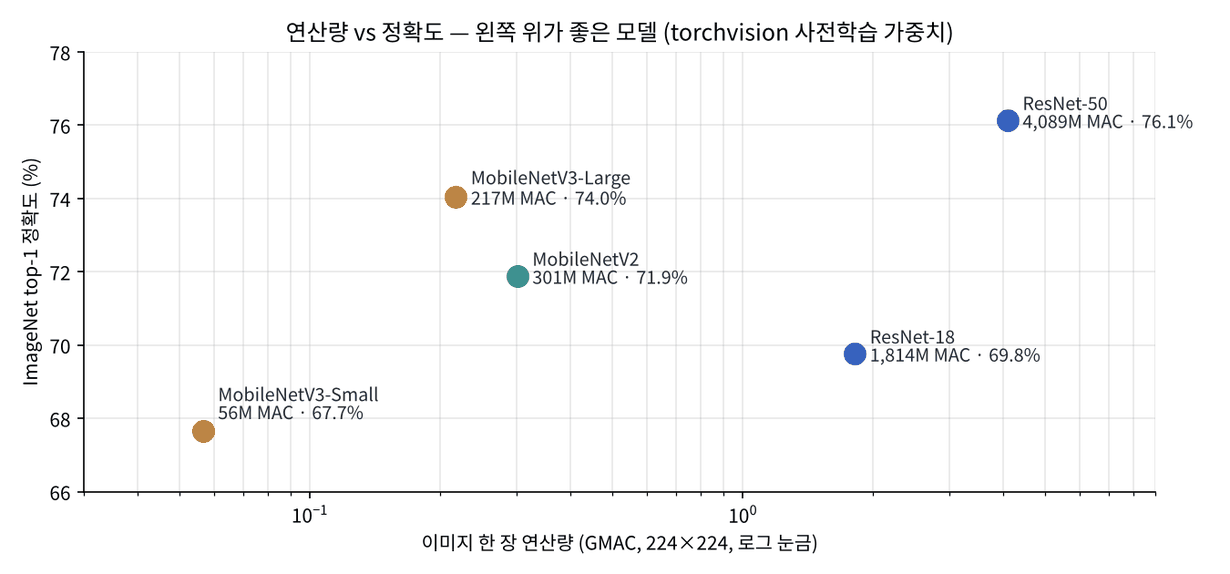

In [ ]:
#@title 🖼 그림 — 모델별 연산량 대비 ImageNet 정확도
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day3/img/f1_tradeoff.png", embed=True, width=820))

ImageNet top-1 정확도 (torchvision 사전학습 가중치 기준): ResNet-18 69.8% · ResNet-50 76.1% · MobileNetV2 71.9% · MobileNetV3-Large 74.0% · MobileNetV3-Small 67.7%. 경량 모델은 **연산량을 수십 분의 1로 줄이면서 정확도는 몇 %p 만** 내줍니다. 왼쪽 위로 갈수록 좋은 모델입니다.

#### 📌 1교시 정리

- 온디바이스 모델 선택 = 정확도 + 지연시간 + 파라미터(메모리) + MAC.
- 지연시간은 CPU · 스레드 1 · 배치 1 · warm-up 후 평균으로 잰다.
- ResNet-50 (4.1G MAC) vs MobileNetV3-Small (56.5M MAC) — 약 72배 차이.

## 2교시 — 연산량 계산: 파라미터 · MAC · 메모리

| 지표 | 의미 | 장치에서 |
|---|---|---|
| 파라미터 수 | 저장해야 할 가중치 개수 | 모델 파일 크기 · 메모리 = 파라미터 × 4 bytes (float32) |
| MAC | 곱셈-덧셈 횟수 (이미지 한 장) | 계산 시간 · 전력 |
| 활성화(activation) 메모리 | 각 층 출력의 크기 | 실행 중 메모리 — 해상도가 클수록 큼 |

어제의 `count_macs` 를 넓혀 활성화 메모리까지 한 번에 재는 함수를 만듭니다.

> 🎬 **애니메이션** [D3-2 연산량 지도](https://imguru-mooc.github.io/AI_CAMPUS/VB-day3/animation.html#d3-2)
> 📝 **워크시트** [2교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day3/worksheet.html#t2)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

**문제 2-1** `model_cost` 를 완성하세요. 합성곱 · Linear 층 **출력의 원소 수**를 모두 더해 활성화 메모리(MB, float32) 를 구합니다.

In [ ]:
def model_cost(model, input_size):
    acts = [0]
    def hook(m, inp, out):
        acts[0] += out.____
    hs = [m.register_forward_hook(hook) for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    model.eval()
    with torch.no_grad():
        model(torch.zeros(input_size, device=next(model.parameters()).device))
    for h in hs: h.remove()
    p = count_params(model)
    return {"params": p, "macs": count_macs(model, input_size),
            "param_MB": p * ____ / 1e6, "act_MB": acts[0] * 4 / 1e6}

for name, m, size in [("ResNet-20", r20, (1, 3, 32, 32)), ("ResNet-50", models_224["ResNet-50"], (1, 3, 224, 224)),
                      ("MobileNetV3-S", models_224["MobileNetV3-S"], (1, 3, 224, 224))]:
    c = model_cost(m, size)
    print(f"{name:14s} 파라미터 {c['param_MB']:7.2f} MB | 활성화 {c['act_MB']:7.2f} MB | MAC {c['macs'] / 1e6:8.1f} M")

In [ ]:
c50 = model_cost(models_224["ResNet-50"], (1, 3, 224, 224))
assert abs(c50["param_MB"] - 25_557_032 * 4 / 1e6) < 1e-6 and c50["act_MB"] > 10; print("✅")

In [ ]:
#@title 🔒 정답 보기 2-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTEg4pSA4pSACmRlZiBtb2RlbF9jb3N0KG1vZGVsLCBpbnB1dF9zaXplKToKICAgIGFj"
    "dHMgPSBbMF0KICAgIGRlZiBob29rKG0sIGlucCwgb3V0KToKICAgICAgICBhY3RzWzBdICs9IG91dC5udW1lbCgp"
    "CiAgICBocyA9IFttLnJlZ2lzdGVyX2ZvcndhcmRfaG9vayhob29rKSBmb3IgbSBpbiBtb2RlbC5tb2R1bGVzKCkg"
    "aWYgaXNpbnN0YW5jZShtLCAobm4uQ29udjJkLCBubi5MaW5lYXIpKV0KICAgIG1vZGVsLmV2YWwoKQogICAgd2l0"
    "aCB0b3JjaC5ub19ncmFkKCk6CiAgICAgICAgbW9kZWwodG9yY2guemVyb3MoaW5wdXRfc2l6ZSwgZGV2aWNlPW5l"
    "eHQobW9kZWwucGFyYW1ldGVycygpKS5kZXZpY2UpKQogICAgZm9yIGggaW4gaHM6IGgucmVtb3ZlKCkKICAgIHAg"
    "PSBjb3VudF9wYXJhbXMobW9kZWwpCiAgICByZXR1cm4geyJwYXJhbXMiOiBwLCAibWFjcyI6IGNvdW50X21hY3Mo"
    "bW9kZWwsIGlucHV0X3NpemUpLAogICAgICAgICAgICAicGFyYW1fTUIiOiBwICogNCAvIDFlNiwgImFjdF9NQiI6"
    "IGFjdHNbMF0gKiA0IC8gMWU2fQoKZm9yIG5hbWUsIG0sIHNpemUgaW4gWygiUmVzTmV0LTIwIiwgcjIwLCAoMSwg"
    "MywgMzIsIDMyKSksICgiUmVzTmV0LTUwIiwgbW9kZWxzXzIyNFsiUmVzTmV0LTUwIl0sICgxLCAzLCAyMjQsIDIy"
    "NCkpLAogICAgICAgICAgICAgICAgICAgICAgKCJNb2JpbGVOZXRWMy1TIiwgbW9kZWxzXzIyNFsiTW9iaWxlTmV0"
    "VjMtUyJdLCAoMSwgMywgMjI0LCAyMjQpKV06CiAgICBjID0gbW9kZWxfY29zdChtLCBzaXplKQogICAgcHJpbnQo"
    "ZiJ7bmFtZToxNHN9IO2MjOudvOuvuO2EsCB7Y1sncGFyYW1fTUInXTo3LjJmfSBNQiB8IO2ZnOyEse2ZlCB7Y1sn"
    "YWN0X01CJ106Ny4yZn0gTUIgfCBNQUMge2NbJ21hY3MnXSAvIDFlNjo4LjFmfSBNIikKCvCfkqEg7ZW07ISkClJl"
    "c05ldC01MCDsnYAg6rCA7KSR7LmY66eMIOyVvSAxMDIgTUIuIOydtOuvuOyngCDtlZwg7J6l7J2EIOyymOumrO2V"
    "mOuKlCDrj5nslYgg7IOd6riw64qUIO2ZnOyEse2ZlOuPhCDsiJjsi60gTUIg7J6F64uI64ukLiDrnbzspojrsqDr"
    "pqztjIzsnbQgNCDsnZgg66mU66qo66asKDRHQikg64qUIOy2qeu2hO2VtCDrs7Tsl6zrj4QsIOy6kOyLnOyXkCDr"
    "k6TslrTqsIDsp4Ag7JWK64qUIO2BsCDrjbDsnbTthLDrpbwg6rOE7IaNIOyYpOqwgOuKlCDqsoPsnbQg7IaN64+E"
    "66W8IOuWqOyWtOucqOumveuLiOuLpC4="
).decode("utf-8"))

### 1×1 Conv 로 줄이기 — bottleneck

ResNet-50 이 ResNet-18 보다 층이 3배 가까이 많은데 MAC 은 2.3배에 그치는 이유는 **bottleneck 블록**입니다. 채널이 많은(256) 곳에서 바로 3×3 을 하지 않고, **1×1 로 채널을 줄이고(64) → 3×3 → 1×1 로 다시 늘립니다**.

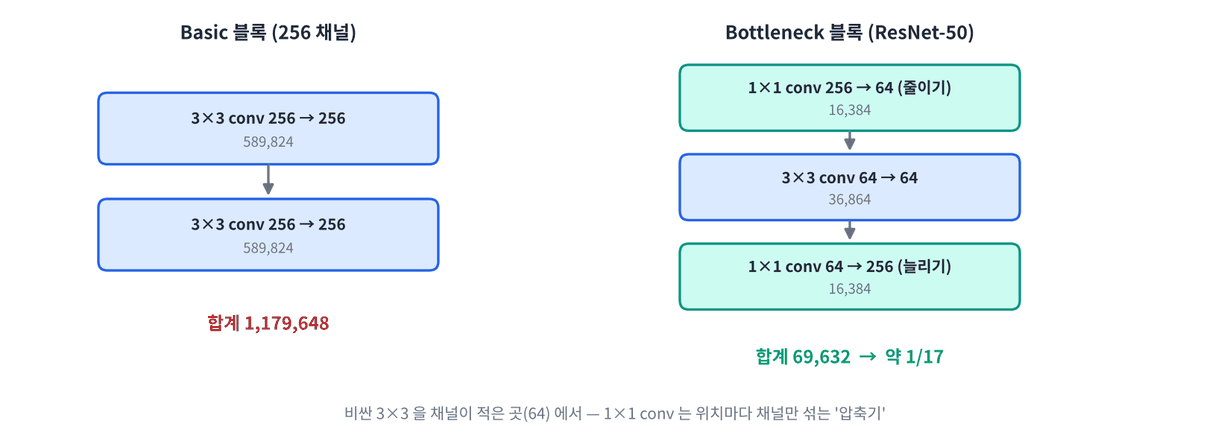

In [ ]:
#@title 🖼 그림 — Basic 블록과 Bottleneck 블록의 파라미터 비교
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day3/img/f2_bottleneck.png", embed=True, width=820))

**문제 2-2** 256 채널 기준으로 두 블록의 가중치 수를 비교하세요 (bias 없음, BN 제외). 어제의 공식 `Cout · Cin · K²` 를 씁니다.

In [ ]:
def w(cin, cout, k):
    return cout * cin * k * k

basic = 2 * w(256, 256, ____)                                    # 3×3 두 번
bottleneck = w(256, ____, 1) + w(64, 64, 3) + w(64, 256, 1)      # 1×1 줄이기 → 3×3 → 1×1 늘리기
print(f"basic {basic:,} | bottleneck {bottleneck:,} | {basic / bottleneck:.1f}배 적음")

In [ ]:
assert (basic, bottleneck) == (1_179_648, 69_632); print("✅")

In [ ]:
#@title 🔒 정답 보기 2-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTIg4pSA4pSACmRlZiB3KGNpbiwgY291dCwgayk6CiAgICByZXR1cm4gY291dCAqIGNp"
    "biAqIGsgKiBrCgpiYXNpYyA9IDIgKiB3KDI1NiwgMjU2LCAzKSAgICAgICAgICAgICAgICAgICAgICAgICAgICAg"
    "ICAgICAgICMgM8OXMyDrkZAg67KICmJvdHRsZW5lY2sgPSB3KDI1NiwgNjQsIDEpICsgdyg2NCwgNjQsIDMpICsg"
    "dyg2NCwgMjU2LCAxKSAgICAgICMgMcOXMSDspITsnbTquLAg4oaSIDPDlzMg4oaSIDHDlzEg64qY66as6riwCnBy"
    "aW50KGYiYmFzaWMge2Jhc2ljOix9IHwgYm90dGxlbmVjayB7Ym90dGxlbmVjazosfSB8IHtiYXNpYyAvIGJvdHRs"
    "ZW5lY2s6LjFmfeuwsCDsoIHsnYwiKQoK8J+SoSDtlbTshKQKMcOXMSBDb252IOuKlCDsnITsuZjrp4jri6Qg7LGE"
    "64SQ64G866as66eMIOyEnuuKlCAn7LGE64SQIOyVley2leq4sCcg7J6F64uI64ukLiDruYTsi7wgM8OXMyDsnYQg"
    "7LGE64SQ7J20IOyggeydgCDqs7MoNjQpIOyXkOyEnCDtlZjrr4DroZwg7JW9IDE367CwIOqwgOuyvOybjOynkeuL"
    "iOuLpC4gM+q1kOyLnCDCtyA06rWQ7Iuc7J2YIE1vYmlsZU5ldCDrj4QgMcOXMSBDb252IOqwgCDtlbXsi6wg67aA"
    "7ZKI7J6F64uI64ukLg=="
).decode("utf-8"))

#### 📌 2교시 정리

- 메모리 = 파라미터 × 4 B + 활성화. 계산 = MAC.
- 1×1 Conv = 채널 섞기 · 압축. bottleneck (1×1 → 3×3 → 1×1) 은 256 채널에서 basic 의 1/17.

## 3교시 — Depthwise Separable Convolution

일반 3×3 합성곱은 **공간(3×3 이웃)** 과 **채널(모든 입력 채널)** 을 한꺼번에 섞습니다. MobileNet 은 이것을 두 단계로 나눕니다.

1. **Depthwise** 3×3 — 채널마다 따로 공간만 섞는다 (`groups = Cin`, Day 2 의 groups)
2. **Pointwise** 1×1 — 위치마다 채널만 섞는다

$$\frac{\text{DS 연산}}{\text{일반 연산}} = \frac{C_{in} K^2 HW + C_{in} C_{out} HW}{C_{in} C_{out} K^2 HW} = \frac{1}{C_{out}} + \frac{1}{K^2}$$

K = 3 이면 약 **1/9 ~ 1/8**.

> 🎬 **애니메이션** [D3-3 Depthwise + Pointwise](https://imguru-mooc.github.io/AI_CAMPUS/VB-day3/animation.html#d3-3)
> 📝 **워크시트** [3교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day3/worksheet.html#t3)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

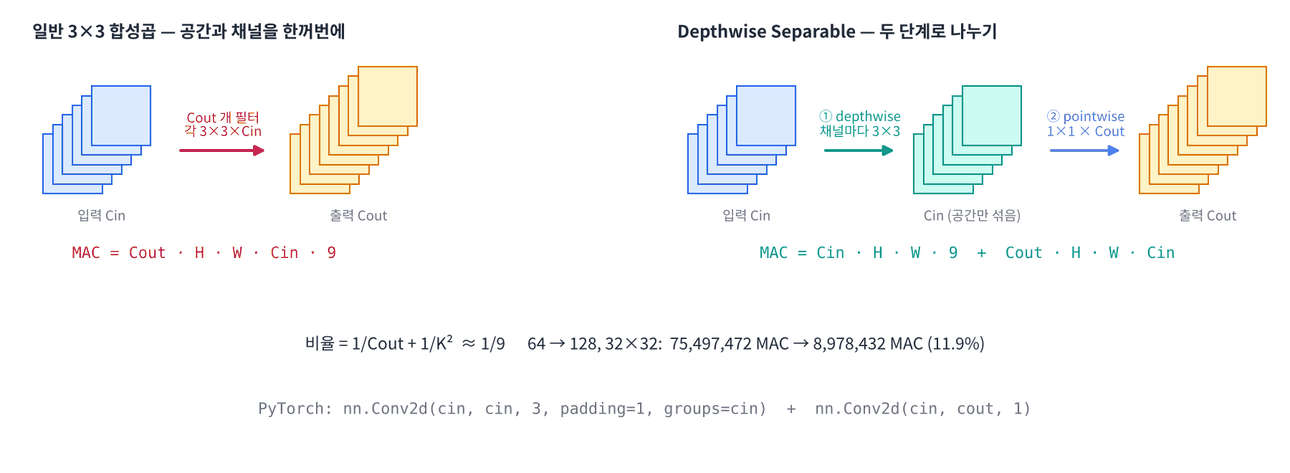

In [ ]:
#@title 🖼 그림 — 일반 합성곱과 Depthwise Separable 합성곱
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day3/img/f3_dsconv.png", embed=True, width=860))

**문제 3-1** Depthwise Separable 블록 `DSConv` 를 완성하세요. 각 단계 뒤에 BN · ReLU 를 붙입니다.

In [ ]:
class DSConv(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.dw = nn.Sequential(nn.Conv2d(cin, cin, 3, stride=stride, padding=1, groups=____, bias=False),
                                nn.BatchNorm2d(cin), nn.ReLU(inplace=True))
        self.pw = nn.Sequential(nn.Conv2d(cin, cout, ____, bias=False),
                                nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

    def forward(self, x):
        return ____

ds = DSConv(64, 128)
std = nn.Sequential(nn.Conv2d(64, 128, 3, padding=1, bias=False), nn.BatchNorm2d(128), nn.ReLU(inplace=True))
print(tuple(ds(torch.zeros(1, 64, 32, 32)).shape), tuple(std(torch.zeros(1, 64, 32, 32)).shape))

In [ ]:
assert ds(torch.zeros(1, 64, 32, 32)).shape == (1, 128, 32, 32); print("✅")

In [ ]:
#@title 🔒 정답 보기 3-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTEg4pSA4pSACmNsYXNzIERTQ29udihubi5Nb2R1bGUpOgogICAgZGVmIF9faW5pdF9f"
    "KHNlbGYsIGNpbiwgY291dCwgc3RyaWRlPTEpOgogICAgICAgIHN1cGVyKCkuX19pbml0X18oKQogICAgICAgIHNl"
    "bGYuZHcgPSBubi5TZXF1ZW50aWFsKG5uLkNvbnYyZChjaW4sIGNpbiwgMywgc3RyaWRlPXN0cmlkZSwgcGFkZGlu"
    "Zz0xLCBncm91cHM9Y2luLCBiaWFzPUZhbHNlKSwKICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICBubi5C"
    "YXRjaE5vcm0yZChjaW4pLCBubi5SZUxVKGlucGxhY2U9VHJ1ZSkpCiAgICAgICAgc2VsZi5wdyA9IG5uLlNlcXVl"
    "bnRpYWwobm4uQ29udjJkKGNpbiwgY291dCwgMSwgYmlhcz1GYWxzZSksCiAgICAgICAgICAgICAgICAgICAgICAg"
    "ICAgICAgICAgbm4uQmF0Y2hOb3JtMmQoY291dCksIG5uLlJlTFUoaW5wbGFjZT1UcnVlKSkKCiAgICBkZWYgZm9y"
    "d2FyZChzZWxmLCB4KToKICAgICAgICByZXR1cm4gc2VsZi5wdyhzZWxmLmR3KHgpKQoKZHMgPSBEU0NvbnYoNjQs"
    "IDEyOCkKc3RkID0gbm4uU2VxdWVudGlhbChubi5Db252MmQoNjQsIDEyOCwgMywgcGFkZGluZz0xLCBiaWFzPUZh"
    "bHNlKSwgbm4uQmF0Y2hOb3JtMmQoMTI4KSwgbm4uUmVMVShpbnBsYWNlPVRydWUpKQpwcmludCh0dXBsZShkcyh0"
    "b3JjaC56ZXJvcygxLCA2NCwgMzIsIDMyKSkuc2hhcGUpLCB0dXBsZShzdGQodG9yY2guemVyb3MoMSwgNjQsIDMy"
    "LCAzMikpLnNoYXBlKSk="
).decode("utf-8"))

**문제 3-2** 64 → 128 채널, 32×32 에서 일반 합성곱과 DS 합성곱의 가중치 수 · MAC 을 비교하고 공식 `1/Cout + 1/K²` 과 맞는지 확인하세요 (BN 제외).

In [ ]:
conv_w = lambda m: sum(c.weight.numel() for c in m.modules() if isinstance(c, nn.Conv2d))
w_std, w_ds = conv_w(std), conv_w(ds)
m_std, m_ds = count_macs(std, (1, 64, 32, 32)), count_macs(ds, (1, 64, 32, 32))
formula = 1 / ____ + 1 / ____
print(f"가중치 {w_std:,} → {w_ds:,}  ({w_ds / w_std:.4f})")
print(f"MAC    {m_std:,} → {m_ds:,}  ({m_ds / m_std:.4f})  | 공식 {formula:.4f}")

In [ ]:
assert (w_std, w_ds, m_std, m_ds) == (73_728, 8_768, 75_497_472, 8_978_432) and abs(m_ds / m_std - formula) < 1e-9; print("✅")

In [ ]:
#@title 🔒 정답 보기 3-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTIg4pSA4pSACmNvbnZfdyA9IGxhbWJkYSBtOiBzdW0oYy53ZWlnaHQubnVtZWwoKSBm"
    "b3IgYyBpbiBtLm1vZHVsZXMoKSBpZiBpc2luc3RhbmNlKGMsIG5uLkNvbnYyZCkpCndfc3RkLCB3X2RzID0gY29u"
    "dl93KHN0ZCksIGNvbnZfdyhkcykKbV9zdGQsIG1fZHMgPSBjb3VudF9tYWNzKHN0ZCwgKDEsIDY0LCAzMiwgMzIp"
    "KSwgY291bnRfbWFjcyhkcywgKDEsIDY0LCAzMiwgMzIpKQpmb3JtdWxhID0gMSAvIDEyOCArIDEgLyA5CnByaW50"
    "KGYi6rCA7KSR7LmYIHt3X3N0ZDosfSDihpIge3dfZHM6LH0gICh7d19kcyAvIHdfc3RkOi40Zn0pIikKcHJpbnQo"
    "ZiJNQUMgICAge21fc3RkOix9IOKGkiB7bV9kczosfSAgKHttX2RzIC8gbV9zdGQ6LjRmfSkgIHwg6rO17IudIHtm"
    "b3JtdWxhOi40Zn0iKQoK8J+SoSDtlbTshKQKZGVwdGh3aXNlIDY0wrc5ID0gNTc2ICsgcG9pbnR3aXNlIDY0wrcx"
    "MjggPSA4LDE5MiDihpIgOCw3NjggKOydvOuwmOydmCAxMS45JSkuIE1BQyDrj4Qg6rCZ7J2AIOu5hOycqC4g7Jew"
    "7IKw7J2YIOuMgOu2gOu2hCg5MyUp7J2AIHBvaW50d2lzZSAxw5cxIOyXkOyEnCDrgpjsmLXri4jri6Qu"
).decode("utf-8"))

**문제 3-3** 실제 속도도 8배 빨라질까요? 같은 층을 CPU 1 스레드로 재 보세요 (입력 64×56×56).

In [ ]:
t_std = latency_ms(std, (1, 64, 56, 56), reps=____)
t_ds = latency_ms(ds, (1, 64, 56, 56), reps=20)
print(f"일반 {t_std:.2f} ms | DS {t_ds:.2f} ms | {t_std / t_ds:.1f}배 빠름 (MAC 기준으로는 {m_std / m_ds:.1f}배)")

In [ ]:
assert t_ds < t_std; print("✅")

In [ ]:
#@title 🔒 정답 보기 3-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTMg4pSA4pSACnRfc3RkID0gbGF0ZW5jeV9tcyhzdGQsICgxLCA2NCwgNTYsIDU2KSwg"
    "cmVwcz0yMCkKdF9kcyA9IGxhdGVuY3lfbXMoZHMsICgxLCA2NCwgNTYsIDU2KSwgcmVwcz0yMCkKcHJpbnQoZiLs"
    "nbzrsJgge3Rfc3RkOi4yZn0gbXMgfCBEUyB7dF9kczouMmZ9IG1zIHwge3Rfc3RkIC8gdF9kczouMWZ967CwIOu5"
    "oOumhCAoTUFDIOq4sOykgOycvOuhnOuKlCB7bV9zdGQgLyBtX2RzOi4xZn3rsLApIikKCvCfkqEg7ZW07ISkCuyL"
    "pO2WiSDsmIg6IOydvOuwmCA1LjE0IG1zIHZzIERTIDEuMjYgbXMg4oaSIDQuMeuwsCAoTUFDIOydgCA4LjTrsLAp"
    "LiBkZXB0aHdpc2Ug64qUIOqzseyFiOydgCDsoIHsp4Drp4wg7LGE64SQ66eI64ukIOuUsOuhnCDrqZTrqqjrpqzr"
    "pbwg7J297Ja0IOqzhOyCsCDrjIDruYQg66mU66qo66asIOydtOuPmeydtCDrp47slYQo66mU66qo66asIOuzkeuq"
    "qSkgTUFDIOunjO2BvCDruajrnbzsp4Dsp4Ag7JWK7Iq164uI64ukLiDqt7jrnpjshJwgKirsi6TsoJwg7J6l7LmY"
    "7JeQ7IScIOyerCDrs7TripQg6rKDKirsnbQg7KSR7JqU7ZWp64uI64ukIChEYXkgNSDCtyBPTk5YwrdUZW5zb3JS"
    "VCku"
).decode("utf-8"))

#### 📌 3교시 정리

- DS Conv = depthwise 3×3 (groups = Cin) + pointwise 1×1. 연산 비율 1/Cout + 1/K² ≈ 1/9.
- 64→128 에서 가중치 73,728 → 8,768. 실제 속도 향상은 MAC 비율보다 작다 (메모리 병목).

## 4교시 — MobileNet V1 · V2 · V3

| 버전 | 해 | 핵심 아이디어 |
|---|---|---|
| V1 | 2017 | 일반 Conv 를 **DS Conv** 로 바꿔 쌓기 |
| V2 | 2018 | **Inverted residual** — 1×1 로 채널을 **늘리고**(×6) → depthwise → 1×1 로 **줄이기**, 마지막 1×1 뒤에는 ReLU 없음(**linear bottleneck**), 크기가 같으면 지름길 |
| V3 | 2019 | 자동 구조 탐색(NAS) + **SE (Squeeze-and-Excitation)** + **h-swish** 활성화 |

ResNet bottleneck 은 '줄였다 늘리기(256→64→256)', MobileNetV2 는 반대로 '늘렸다 줄이기(24→144→24)' 라서 *inverted* 입니다. depthwise 는 싸기 때문에 채널을 늘린 곳에서 해도 부담이 적고, 블록 사이를 지나는 텐서는 얇아(24채널) 메모리가 적게 듭니다.

> 🎬 **애니메이션** [D3-4 Inverted residual · SE](https://imguru-mooc.github.io/AI_CAMPUS/VB-day3/animation.html#d3-4)
> 📝 **워크시트** [4교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day3/worksheet.html#t4)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

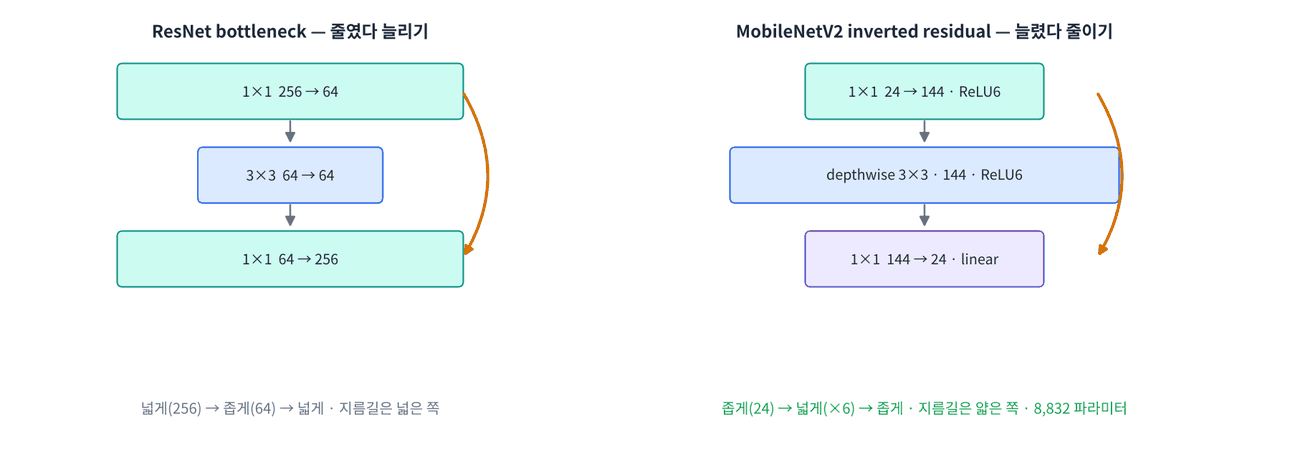

In [ ]:
#@title 🖼 그림 — ResNet bottleneck 과 MobileNetV2 inverted residual 비교
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day3/img/f4_inverted.png", embed=True, width=860))

**문제 4-1** MobileNetV2 의 `InvertedResidual` 블록을 완성하세요. 마지막 1×1 뒤에는 **활성화를 넣지 않습니다** (linear bottleneck).

In [ ]:
class InvertedResidual(nn.Module):
    def __init__(self, cin, cout, stride=1, t=6):
        super().__init__()
        hid = cin * t
        self.use_res = stride == 1 and ____
        self.block = nn.Sequential(
            nn.Conv2d(cin, hid, 1, bias=False), nn.BatchNorm2d(hid), nn.ReLU6(inplace=True),                        # 늘리기
            nn.Conv2d(hid, hid, 3, stride, 1, groups=____, bias=False), nn.BatchNorm2d(hid), nn.ReLU6(inplace=True),  # depthwise
            nn.Conv2d(hid, cout, 1, bias=False), nn.BatchNorm2d(cout),                                               # 줄이기 (linear)
        )

    def forward(self, x):
        out = self.block(x)
        return ____ if self.use_res else out

ir1, ir2 = InvertedResidual(24, 24), InvertedResidual(16, 24, stride=2)
print(count_params(ir1), count_params(ir2), tuple(ir1(torch.zeros(1, 24, 16, 16)).shape), tuple(ir2(torch.zeros(1, 16, 32, 32)).shape))

In [ ]:
assert count_params(ir1) == 8_832 and count_params(ir2) == 5_136 and ir1.use_res and not ir2.use_res; print("✅")

In [ ]:
#@title 🔒 정답 보기 4-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTEg4pSA4pSACmNsYXNzIEludmVydGVkUmVzaWR1YWwobm4uTW9kdWxlKToKICAgIGRl"
    "ZiBfX2luaXRfXyhzZWxmLCBjaW4sIGNvdXQsIHN0cmlkZT0xLCB0PTYpOgogICAgICAgIHN1cGVyKCkuX19pbml0"
    "X18oKQogICAgICAgIGhpZCA9IGNpbiAqIHQKICAgICAgICBzZWxmLnVzZV9yZXMgPSBzdHJpZGUgPT0gMSBhbmQg"
    "Y2luID09IGNvdXQKICAgICAgICBzZWxmLmJsb2NrID0gbm4uU2VxdWVudGlhbCgKICAgICAgICAgICAgbm4uQ29u"
    "djJkKGNpbiwgaGlkLCAxLCBiaWFzPUZhbHNlKSwgbm4uQmF0Y2hOb3JtMmQoaGlkKSwgbm4uUmVMVTYoaW5wbGFj"
    "ZT1UcnVlKSwgICAgICAgICAgICAgICAgICAgICAgICAjIOuKmOumrOq4sAogICAgICAgICAgICBubi5Db252MmQo"
    "aGlkLCBoaWQsIDMsIHN0cmlkZSwgMSwgZ3JvdXBzPWhpZCwgYmlhcz1GYWxzZSksIG5uLkJhdGNoTm9ybTJkKGhp"
    "ZCksIG5uLlJlTFU2KGlucGxhY2U9VHJ1ZSksICAjIGRlcHRod2lzZQogICAgICAgICAgICBubi5Db252MmQoaGlk"
    "LCBjb3V0LCAxLCBiaWFzPUZhbHNlKSwgbm4uQmF0Y2hOb3JtMmQoY291dCksICAgICAgICAgICAgICAgICAgICAg"
    "ICAgICAgICAgICAgICAgICAgICAgICAgICAjIOykhOydtOq4sCAobGluZWFyKQogICAgICAgICkKCiAgICBkZWYg"
    "Zm9yd2FyZChzZWxmLCB4KToKICAgICAgICBvdXQgPSBzZWxmLmJsb2NrKHgpCiAgICAgICAgcmV0dXJuIHggKyBv"
    "dXQgaWYgc2VsZi51c2VfcmVzIGVsc2Ugb3V0CgppcjEsIGlyMiA9IEludmVydGVkUmVzaWR1YWwoMjQsIDI0KSwg"
    "SW52ZXJ0ZWRSZXNpZHVhbCgxNiwgMjQsIHN0cmlkZT0yKQpwcmludChjb3VudF9wYXJhbXMoaXIxKSwgY291bnRf"
    "cGFyYW1zKGlyMiksIHR1cGxlKGlyMSh0b3JjaC56ZXJvcygxLCAyNCwgMTYsIDE2KSkuc2hhcGUpLCB0dXBsZShp"
    "cjIodG9yY2guemVyb3MoMSwgMTYsIDMyLCAzMikpLnNoYXBlKSkKCvCfkqEg7ZW07ISkCmlyMTogMcOXMSAyNOKG"
    "kjE0NCAzLDQ1NiArIEJOIDI4OCDCtyBkZXB0aHdpc2UgMTQ0wrc5ID0gMSwyOTYgKyBCTiAyODggwrcgMcOXMSAx"
    "NDTihpIyNCAzLDQ1NiArIEJOIDQ4ID0gOCw4MzIuIOuniOyngOunieyXkCBSZUxVIOulvCDrhKPsnLzrqbQg7LGE"
    "64SQ7J20IOyggeydgCgyNCkg7Lac66Cl7JeQ7IScIOydjOyImCDsoJXrs7TqsIAg7J6Y66CkIOyGkOyLpOydtCDt"
    "gazri6TripQg6rKD7J20IFYyIOuFvOusuOydmCDqtIDssLDsnoXri4jri6Qu"
).decode("utf-8"))

### MobileNetV3 의 두 부품 — h-swish 와 SE

- **h-swish** (hard swish): $x \cdot \dfrac{\mathrm{ReLU6}(x + 3)}{6}$ — swish($x \cdot \sigma(x)$) 를 sigmoid 없이 근사. 장치에서 계산이 싸다.
- **SE (Squeeze-and-Excitation)**: 채널마다 평균(squeeze) → 작은 FC 두 개 → 0~1 가중치(excitation) → 채널마다 곱하기. '어떤 채널이 지금 중요한가' 를 이미지마다 다시 정한다.

**문제 4-2** h-swish 를 직접 구현해 `nn.Hardswish` 와 비교하고, swish 와 함께 그려 보세요.

In [ ]:
def h_swish(x):
    return x * F.relu6(x ____) / ____

x = torch.linspace(-6, 6, 241)

In [ ]:
assert torch.allclose(h_swish(x), nn.Hardswish()(x)); print("✅")
plt.figure(figsize=(6, 3.2))
plt.plot(x, F.relu(x), label="ReLU"); plt.plot(x, x * torch.sigmoid(x), label="swish"); plt.plot(x, h_swish(x), "--", label="h-swish")
plt.legend(); plt.grid(alpha=.3); plt.title("activations"); plt.show()

In [ ]:
#@title 🔒 정답 보기 4-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTIg4pSA4pSACmRlZiBoX3N3aXNoKHgpOgogICAgcmV0dXJuIHggKiBGLnJlbHU2KHgg"
    "KyAzKSAvIDYKCnggPSB0b3JjaC5saW5zcGFjZSgtNiwgNiwgMjQxKQoK8J+SoSDtlbTshKQKeCDiiaQg4oiSMyDs"
    "nbTrqbQgMCwgeCDiiaUgMyDsnbTrqbQgeCwg6re4IOyCrOydtOuKlCAy7LCoIOqzoeyEoC4gc2lnbW9pZChleHAp"
    "IOuMgOyLoCBSZUxVNiDCtyDqs7Egwrcg64KY64iX7IWI66eMIOyNqOyEnCBpbnQ4IOyWkeyekO2ZlOyXkOuPhCDs"
    "nKDrpqztlanri4jri6QgKFF1YW50aXphdGlvbiDqs7zrqqkpLg=="
).decode("utf-8"))

**문제 4-3** torchvision `mobilenet_v3_small` 의 구조를 살펴보세요. `features` 안의 블록 수, SE 가 들어간 블록 수, 마지막 특징맵 채널을 구합니다.

In [ ]:
mnv3 = torchvision.models.mobilenet_v3_small(weights=None)
blocks = [b for b in mnv3.features if b.__class__.__name__ == "____"]
n_se = sum(any(m.__class__.__name__ == "SqueezeExcitation" for m in b.modules()) for b in blocks)
feat = mnv3.features(torch.zeros(1, 3, 224, 224))
print("InvertedResidual 블록:", len(blocks), "| SE 블록:", n_se, "| 마지막 특징맵:", tuple(feat.shape))
print(mnv3.classifier)

In [ ]:
assert len(blocks) == 11 and n_se == 9 and feat.shape == (1, 576, 7, 7); print("✅")

In [ ]:
#@title 🔒 정답 보기 4-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTMg4pSA4pSACm1udjMgPSB0b3JjaHZpc2lvbi5tb2RlbHMubW9iaWxlbmV0X3YzX3Nt"
    "YWxsKHdlaWdodHM9Tm9uZSkKYmxvY2tzID0gW2IgZm9yIGIgaW4gbW52My5mZWF0dXJlcyBpZiBiLl9fY2xhc3Nf"
    "Xy5fX25hbWVfXyA9PSAiSW52ZXJ0ZWRSZXNpZHVhbCJdCm5fc2UgPSBzdW0oYW55KG0uX19jbGFzc19fLl9fbmFt"
    "ZV9fID09ICJTcXVlZXplRXhjaXRhdGlvbiIgZm9yIG0gaW4gYi5tb2R1bGVzKCkpIGZvciBiIGluIGJsb2NrcykK"
    "ZmVhdCA9IG1udjMuZmVhdHVyZXModG9yY2guemVyb3MoMSwgMywgMjI0LCAyMjQpKQpwcmludCgiSW52ZXJ0ZWRS"
    "ZXNpZHVhbCDruJTroZ06IiwgbGVuKGJsb2NrcyksICJ8IFNFIOu4lOuhnToiLCBuX3NlLCAifCDrp4jsp4Drp4kg"
    "7Yq57KeV66e1OiIsIHR1cGxlKGZlYXQuc2hhcGUpKQpwcmludChtbnYzLmNsYXNzaWZpZXIpCgrwn5KhIO2VtOyE"
    "pAoxMeqwnCDruJTroZ0g7KSRIDnqsJzsl5AgU0UuIOuniOyngOuniSDtirnsp5Xrp7UgKDU3NiwgNywgNykg4oaS"
    "IEdBUCDihpIgY2xhc3NpZmllcjogTGluZWFyKDU3NuKGkjEwMjQpIMK3IEhhcmRzd2lzaCDCtyBEcm9wb3V0IMK3"
    "IExpbmVhcigxMDI04oaSMTAwMCkuIOyghOyytCAyLDU0Miw4NTYg7YyM652866+47YSwLCAyMjTDlzIyNCDsl5Ds"
    "hJwgNTYuNU0gTUFDLg=="
).decode("utf-8"))

#### 📌 4교시 정리

- V1: DS Conv. V2: inverted residual (늘리고 → depthwise → 줄이기, linear bottleneck, 지름길). V3: NAS + SE + h-swish.
- MobileNetV3-Small: 블록 11개 (SE 9개), 2.54M 파라미터, 56.5M MAC — ResNet-50 의 1/72.

## 5교시 — 전이학습 (transfer learning)

ImageNet (1,000 클래스 · 128만 장) 으로 학습된 모델의 앞쪽 층은 **에지 · 질감 · 모양** 같은 일반적인 특징을 이미 압니다. 그 특징 추출기(`features`) 는 그대로 가져오고, 마지막 분류기만 우리 클래스 수(10) 로 바꿔 학습하는 것이 전이학습입니다.

| 방법 | 학습하는 부분 | 장점 | 언제 |
|---|---|---|---|
| **feature extraction** | 분류기만 (features 동결) | 빠르고 과적합이 적다 | 데이터가 아주 적을 때, 원래 데이터와 비슷할 때 |
| **fine-tuning** | 전체 (작은 학습률) | 정확도가 높다 | 데이터가 어느 정도 있을 때 |

**주의** — 사전학습 모델은 학습 때와 같은 전처리를 기대합니다: RGB, 0~1 → **ImageNet 평균 · 표준편차**로 정규화. CIFAR 상수를 쓰면 안 됩니다. 입력 크기도 너무 작으면 특징이 사라지므로 32 → **96** 으로 키워 넣습니다.

> 🎬 **애니메이션** [D3-5 전이학습 — 동결과 미세조정](https://imguru-mooc.github.io/AI_CAMPUS/VB-day3/animation.html#d3-5)
> 📝 **워크시트** [5교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day3/worksheet.html#t5)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

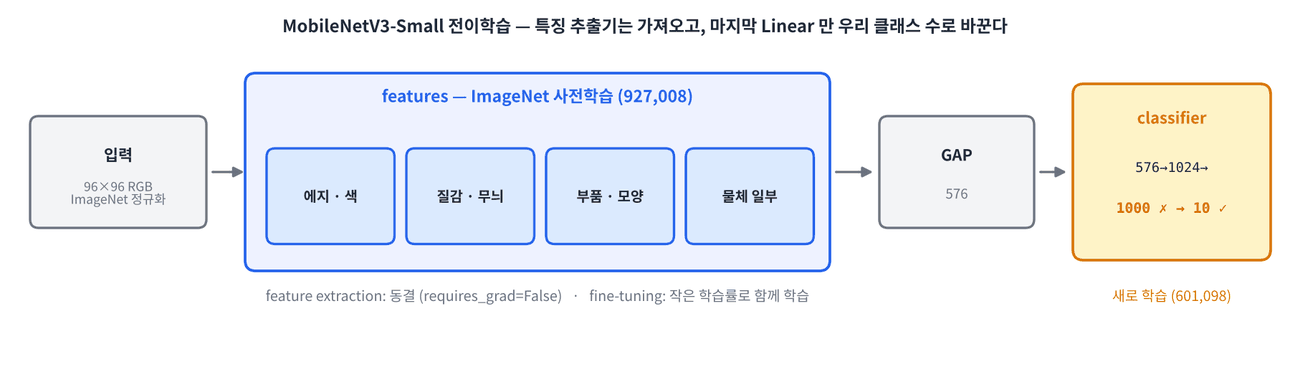

In [ ]:
#@title 🖼 그림 — 전이학습 — 특징 추출기는 가져오고 분류기만 바꾼다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day3/img/f5_transfer.png", embed=True, width=860))

**문제 5-1** ImageNet 사전학습 MobileNetV3-Small 을 불러오고, 마지막 Linear 를 10 클래스로 바꾸세요. `W_MNV3S.transforms()` 는 이 가중치가 기대하는 전처리를 알려 줍니다.

In [ ]:
torch.manual_seed(0)
mnet = torchvision.models.mobilenet_v3_small(weights=____)
print(W_MNV3S.transforms())
mnet.classifier[____] = nn.Linear(1024, ____)
mnet = mnet.to(device)
print("파라미터:", f"{count_params(mnet):,}", "| features:", f"{count_params(mnet.features):,}", "| classifier:", f"{count_params(mnet.classifier):,}")

In [ ]:
assert count_params(mnet) == 1_528_106 and mnet(torch.zeros(2, 3, IMG, IMG, device=device)).shape == (2, 10); print("✅")

In [ ]:
#@title 🔒 정답 보기 5-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTEg4pSA4pSACnRvcmNoLm1hbnVhbF9zZWVkKDApCm1uZXQgPSB0b3JjaHZpc2lvbi5t"
    "b2RlbHMubW9iaWxlbmV0X3YzX3NtYWxsKHdlaWdodHM9V19NTlYzUykKcHJpbnQoV19NTlYzUy50cmFuc2Zvcm1z"
    "KCkpCm1uZXQuY2xhc3NpZmllclszXSA9IG5uLkxpbmVhcigxMDI0LCAxMCkKbW5ldCA9IG1uZXQudG8oZGV2aWNl"
    "KQpwcmludCgi7YyM652866+47YSwOiIsIGYie2NvdW50X3BhcmFtcyhtbmV0KTosfSIsICJ8IGZlYXR1cmVzOiIs"
    "IGYie2NvdW50X3BhcmFtcyhtbmV0LmZlYXR1cmVzKTosfSIsICJ8IGNsYXNzaWZpZXI6IiwgZiJ7Y291bnRfcGFy"
    "YW1zKG1uZXQuY2xhc3NpZmllcik6LH0iKQoK8J+SoSDtlbTshKQKMTAwMCDtgbTrnpjsiqTsmqkgTGluZWFyKDEw"
    "MjTihpIxMDAwKSAxLDAyNSwwMDAg6rCc6rCAIExpbmVhcigxMDI04oaSMTApIDEwLDI1MCDqsJzroZwg67CU64CM"
    "7Ja0IOyghOyytCAyLDU0Miw4NTYg4oaSIDEsNTI4LDEwNi4g7Lac66Cl65CcIHRyYW5zZm9ybXMg7J2YIG1lYW4v"
    "c3RkIOqwgCBJTU5FVF9NRUFOLCBJTU5FVF9TVEQg7JmAIOqwmeydgCDqsoPsnYQg7ZmV7J247ZWY7IS47JqULg=="
).decode("utf-8"))

**문제 5-2** **feature extraction** — `features` 의 모든 파라미터를 동결(`requires_grad = False`) 하고, 학습되는 파라미터만 옵티마이저에 넘겨 **1 epoch** 학습하세요. (증강 없는 `train_mn_plain` 사용, T4 로 약 30초)

In [ ]:
fe = copy.deepcopy(mnet)
for p in fe.features.parameters():
    p.requires_grad = ____
n_train = count_params(fe, trainable_only=True)
plain_loader = DataLoader(train_mn_plain, batch_size=128, shuffle=True, num_workers=NW, pin_memory=True)
opt = torch.optim.Adam([p for p in fe.parameters() if p.____], lr=1e-3)
hist_fe = fit(fe, plain_loader, test_mn_loader, 1, opt, label="feature extraction")
print(f"학습되는 파라미터 {n_train:,} / {count_params(fe):,}")

In [ ]:
assert n_train == 601_098 and hist_fe["test_acc"][-1] > 0.5; print("✅")

In [ ]:
#@title 🔒 정답 보기 5-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTIg4pSA4pSACmZlID0gY29weS5kZWVwY29weShtbmV0KQpmb3IgcCBpbiBmZS5mZWF0"
    "dXJlcy5wYXJhbWV0ZXJzKCk6CiAgICBwLnJlcXVpcmVzX2dyYWQgPSBGYWxzZQpuX3RyYWluID0gY291bnRfcGFy"
    "YW1zKGZlLCB0cmFpbmFibGVfb25seT1UcnVlKQpwbGFpbl9sb2FkZXIgPSBEYXRhTG9hZGVyKHRyYWluX21uX3Bs"
    "YWluLCBiYXRjaF9zaXplPTEyOCwgc2h1ZmZsZT1UcnVlLCBudW1fd29ya2Vycz1OVywgcGluX21lbW9yeT1UcnVl"
    "KQpvcHQgPSB0b3JjaC5vcHRpbS5BZGFtKFtwIGZvciBwIGluIGZlLnBhcmFtZXRlcnMoKSBpZiBwLnJlcXVpcmVz"
    "X2dyYWRdLCBscj0xZS0zKQpoaXN0X2ZlID0gZml0KGZlLCBwbGFpbl9sb2FkZXIsIHRlc3RfbW5fbG9hZGVyLCAx"
    "LCBvcHQsIGxhYmVsPSJmZWF0dXJlIGV4dHJhY3Rpb24iKQpwcmludChmIu2VmeyKteuQmOuKlCDtjIzrnbzrr7jt"
    "hLAge25fdHJhaW46LH0gLyB7Y291bnRfcGFyYW1zKGZlKTosfSIpCgrwn5KhIO2VtOyEpArtlZnsirXrkJjripQg"
    "6rKD7J2AIGNsYXNzaWZpZXIgNjAxLDA5OCDqsJwoMzklKSDrv5AuIOyLpO2WiSDsmIggMSBlcG9jaCB0ZXN0IDAu"
    "NjYwNyDigJQg67aE66WY6riw66eMIOuwlOq/lCDrgbzsm4zrj4QgSW1hZ2VOZXQg7Yq57KeV66eM7Jy866GcIOyd"
    "tCDsoJXrj4TqsIAg64KY7Ji164uI64ukLg=="
).decode("utf-8"))

**문제 5-3** **fine-tuning** — 같은 사전학습 모델을 동결 없이 전체 학습하세요 (Adam 1e-3, 1 epoch). 처음부터 학습한 모델이 1 epoch 에 어디까지 가는지도 함께 봅니다.

In [ ]:
ft = copy.deepcopy(mnet)
opt = torch.optim.Adam(ft.parameters(), lr=____)
hist_ft = fit(ft, plain_loader, test_mn_loader, 1, opt, label="fine-tuning      ")

torch.manual_seed(0)
scratch = torchvision.models.mobilenet_v3_small(weights=____, num_classes=10)
scratch = set_bn_momentum(scratch).to(device)        # 처음부터 학습할 때는 BN running 평균이 빨리 따라오도록 (6교시 참고)
opt = torch.optim.Adam(scratch.parameters(), lr=1e-3)
hist_sc = fit(scratch, plain_loader, test_mn_loader, 1, opt, label="from scratch     ")

In [ ]:
assert hist_ft["test_acc"][-1] > hist_fe["test_acc"][-1] and hist_ft["test_acc"][-1] > hist_sc["test_acc"][-1]; print("✅")

In [ ]:
#@title 🔒 정답 보기 5-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTMg4pSA4pSACmZ0ID0gY29weS5kZWVwY29weShtbmV0KQpvcHQgPSB0b3JjaC5vcHRp"
    "bS5BZGFtKGZ0LnBhcmFtZXRlcnMoKSwgbHI9MWUtMykKaGlzdF9mdCA9IGZpdChmdCwgcGxhaW5fbG9hZGVyLCB0"
    "ZXN0X21uX2xvYWRlciwgMSwgb3B0LCBsYWJlbD0iZmluZS10dW5pbmcgICAgICAiKQoKdG9yY2gubWFudWFsX3Nl"
    "ZWQoMCkKc2NyYXRjaCA9IHRvcmNodmlzaW9uLm1vZGVscy5tb2JpbGVuZXRfdjNfc21hbGwod2VpZ2h0cz1Ob25l"
    "LCBudW1fY2xhc3Nlcz0xMCkKc2NyYXRjaCA9IHNldF9ibl9tb21lbnR1bShzY3JhdGNoKS50byhkZXZpY2UpICAg"
    "ICAgICAjIOyymOydjOu2gO2EsCDtlZnsirXtlaAg65WM64qUIEJOIHJ1bm5pbmcg7Y+J6reg7J20IOu5qOumrCDr"
    "lLDrnbzsmKTrj4TroZ0gKDbqtZDsi5wg7LC46rOgKQpvcHQgPSB0b3JjaC5vcHRpbS5BZGFtKHNjcmF0Y2gucGFy"
    "YW1ldGVycygpLCBscj0xZS0zKQpoaXN0X3NjID0gZml0KHNjcmF0Y2gsIHBsYWluX2xvYWRlciwgdGVzdF9tbl9s"
    "b2FkZXIsIDEsIG9wdCwgbGFiZWw9ImZyb20gc2NyYXRjaCAgICAgIikKCvCfkqEg7ZW07ISkCuyLpO2WiSDsmIgg"
    "KDEgZXBvY2gpOiBmZWF0dXJlIGV4dHJhY3Rpb24gMC42NjA3IMK3IGZpbmUtdHVuaW5nIDAuODI3MyDCtyDsspjs"
    "nYzrtoDthLAgMC41NDcwLiDqsJnsnYAg6rWs7KGwIMK3IOqwmeydgCAxIGVwb2NoIOyduOuNsCDsgqzsoITtlZns"
    "irUg6rCA7KSR7LmY7JeQ7IScIOyLnOyeke2VmOuptCDtm6jslKwg7JWe7IScIOy2nOuwnO2VqeuLiOuLpC4g7KCE"
    "7LK066W8IOyhsOq4iOyUqSDqs6DsuZjripQgZmluZS10dW5pbmcg7J20IOu2hOulmOq4sOunjCDtlZnsirXtlZjr"
    "ipQg6rKD67O064ukIOuGkuyKteuLiOuLpCDigJQgQ0lGQVItMTAg7IKs7KeE7J20IEltYWdlTmV0IOqzvCDqvaQg"
    "64uk66W06riwKDMyw5czMiwg7Z2Q66a8KSDrlYzrrLjsnoXri4jri6Qu"
).decode("utf-8"))

#### ⚠️ 자주 하는 실수

- 사전학습 모델에 CIFAR 정규화 상수를 씀 → ImageNet 평균 · 표준편차로.
- 동결한 뒤에도 `model.parameters()` 전체를 옵티마이저에 넘김 → 동작은 하지만 의도가 흐려집니다. 학습할 파라미터만 넘기세요.
- 동결한 층의 BN 은 `model.train()` 에서 running 통계가 계속 바뀝니다 — 엄격하게 고정하려면 그 층만 `eval()` 로 둡니다.

#### 📌 5교시 정리

- 전이학습 = 사전학습 특징 추출기 + 새 분류기. `mnet.classifier[3] = nn.Linear(1024, 10)`.
- feature extraction (동결, 601,098 개 학습) vs fine-tuning (전체). 전처리는 사전학습 때와 같게.

## 6교시 — 적은 데이터와 전이학습

현장에서는 클래스당 수천 장을 모으기 어렵습니다 (안전모 착용 / 미착용 사진을 클래스당 100장 모으는 것도 일입니다). 전이학습의 진짜 힘은 **데이터가 적을 때** 나옵니다. CIFAR-10 에서 **클래스당 100장 (총 1,000장)** 만 쓰는 상황을 만들어 실험합니다.

> 🎬 **애니메이션** [D3-6 적은 데이터 실험](https://imguru-mooc.github.io/AI_CAMPUS/VB-day3/animation.html#d3-6)
> 📝 **워크시트** [6교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day3/worksheet.html#t6)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

**문제 6-1** 클래스마다 앞에서 100장씩 골라 **균형 잡힌** 1,000장 인덱스를 만드세요. `train_mn.targets` 는 50,000개 레이블 리스트입니다.

In [ ]:
targets = np.array(train_mn.targets)
idx_small = np.concatenate([np.where(targets == c)[0][:____] for c in range(____)])
small_loader = DataLoader(Subset(train_mn, idx_small), batch_size=64, shuffle=True, num_workers=NW)
print(len(idx_small), np.bincount(targets[idx_small]))

In [ ]:
assert len(idx_small) == 1000 and (np.bincount(targets[idx_small]) == 100).all(); print("✅")

In [ ]:
#@title 🔒 정답 보기 6-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTEg4pSA4pSACnRhcmdldHMgPSBucC5hcnJheSh0cmFpbl9tbi50YXJnZXRzKQppZHhf"
    "c21hbGwgPSBucC5jb25jYXRlbmF0ZShbbnAud2hlcmUodGFyZ2V0cyA9PSBjKVswXVs6MTAwXSBmb3IgYyBpbiBy"
    "YW5nZSgxMCldKQpzbWFsbF9sb2FkZXIgPSBEYXRhTG9hZGVyKFN1YnNldCh0cmFpbl9tbiwgaWR4X3NtYWxsKSwg"
    "YmF0Y2hfc2l6ZT02NCwgc2h1ZmZsZT1UcnVlLCBudW1fd29ya2Vycz1OVykKcHJpbnQobGVuKGlkeF9zbWFsbCks"
    "IG5wLmJpbmNvdW50KHRhcmdldHNbaWR4X3NtYWxsXSkpCgrwn5KhIO2VtOyEpArrjbDsnbTthLDrpbwg7KeB7KCR"
    "IOuqqOydhCDrlYzrj4Qg7YG0656Y7Iqk67OEIOqwnOyImOu2gO2EsCDtmZXsnbjtlanri4jri6QgKG5wLmJpbmNv"
    "dW50KS4g7ZWc7Kq97J20IO2bqOyUrCDrp47snLzrqbQg66qo64247J20IOq3uOyqveycvOuhnCDquLDsm4Hri4jr"
    "i6Qg4oCUIOyViOyghCDrjbDsnbTthLDsl5DshJwgJ+uvuOywqeyaqScg7J20IOyggeydgCDqsr3smrDqsIAg7Z2U"
    "7ZWp64uI64ukLg=="
).decode("utf-8"))

**문제 6-2** 1,000장으로 **처음부터** 학습한 모델과 **사전학습 fine-tuning** 모델을 같은 조건(증강, Adam 1e-3, 10 epoch) 으로 비교하세요. (T4 로 둘 합쳐 약 1분)

In [ ]:
small_res = {}
for name, w in [("scratch", None), ("pretrained", W_MNV3S)]:
    torch.manual_seed(0)
    m = torchvision.models.mobilenet_v3_small(weights=____)
    m.classifier[3] = nn.Linear(1024, 10)
    m = set_bn_momentum(m).to(device)            # 두 모델 모두 BN momentum 0.1 (아래 설명)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    h = fit(m, ____, test_mn_loader, ____, opt, label=f"{name:10s}")
    small_res[name] = (m, h)

In [ ]:
a_sc, a_pt = small_res["scratch"][1]["test_acc"][-1], small_res["pretrained"][1]["test_acc"][-1]
print(f"1,000장 · 10 epoch — 처음부터 {a_sc:.4f} vs 사전학습 {a_pt:.4f}")
assert a_pt > a_sc + 0.15; print("✅")
plt.figure(figsize=(6, 3.5))
for k, (_, h) in small_res.items(): plt.plot(range(1, 11), h["test_acc"], "o-", label=k)
plt.xlabel("epoch"); plt.ylabel("test accuracy"); plt.title("1,000 training images"); plt.grid(alpha=.3); plt.legend(); plt.show()

In [ ]:
#@title 🔒 정답 보기 6-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTIg4pSA4pSACnNtYWxsX3JlcyA9IHt9CmZvciBuYW1lLCB3IGluIFsoInNjcmF0Y2gi"
    "LCBOb25lKSwgKCJwcmV0cmFpbmVkIiwgV19NTlYzUyldOgogICAgdG9yY2gubWFudWFsX3NlZWQoMCkKICAgIG0g"
    "PSB0b3JjaHZpc2lvbi5tb2RlbHMubW9iaWxlbmV0X3YzX3NtYWxsKHdlaWdodHM9dykKICAgIG0uY2xhc3NpZmll"
    "clszXSA9IG5uLkxpbmVhcigxMDI0LCAxMCkKICAgIG0gPSBzZXRfYm5fbW9tZW50dW0obSkudG8oZGV2aWNlKSAg"
    "ICAgICAgICAgICMg65GQIOuqqOuNuCDrqqjrkZAgQk4gbW9tZW50dW0gMC4xICjslYTrnpgg7ISk66qFKQogICAg"
    "b3B0ID0gdG9yY2gub3B0aW0uQWRhbShtLnBhcmFtZXRlcnMoKSwgbHI9MWUtMykKICAgIGggPSBmaXQobSwgc21h"
    "bGxfbG9hZGVyLCB0ZXN0X21uX2xvYWRlciwgMTAsIG9wdCwgbGFiZWw9ZiJ7bmFtZToxMHN9IikKICAgIHNtYWxs"
    "X3Jlc1tuYW1lXSA9IChtLCBoKQoK8J+SoSDtlbTshKQK7Iuk7ZaJIOyYiDog7LKY7J2M67aA7YSwIDAuMzU2MCB2"
    "cyDsgqzsoITtlZnsirUgMC42NTYxLiDrjbDsnbTthLDqsIAgNTDrsLAg7KCB7Ja064+EIOyCrOyghO2VmeyKtSDr"
    "qqjrjbjsnYAg6r2kIOyTuCDrp4ztlZwg7KCV7ZmV64+E66W8IOuCtOyngOunjCwg7LKY7J2M67aA7YSwIO2VmeyK"
    "te2VnCDrqqjrjbjsnYAgMSwwMDDsnqXsl5DshJwg7J2867CY7KCB7J24IO2KueynleydhCDrsLDsmrgg7IiYIOyX"
    "huyKteuLiOuLpC4g7ZiE7J6lIOuNsOydtO2EsOqwgCDsoIHsnYTsiJjroZ0g7KCE7J207ZWZ7Iq17J20IOy2nOuw"
    "nOygkOyeheuLiOuLpC4="
).decode("utf-8"))

#### ⚠️ BN momentum 함정 — Day 2 BatchNorm 복습

torchvision MobileNetV3 의 BatchNorm 은 `momentum=0.01` 입니다. running 평균 · 분산이 step 마다 1% 씩만 새 배치 쪽으로 움직인다는 뜻입니다. 1,000장 · 배치 64 면 epoch 당 16 step — 10 epoch 해도 160 step 이라 **처음부터 학습한 모델의 running 통계가 초기값(평균 0 · 분산 1) 에서 거의 못 벗어납니다**. 그러면 `model.train()` 에서는 학습이 되는데(train 정확도 상승) `model.eval()` 에서는 엉뚱한 통계로 정규화해 **test 가 0.10 (찍기)** 으로 나옵니다. 사전학습 모델은 ImageNet 의 running 통계를 이미 갖고 있어 이 문제가 작습니다.

그래서 위 실험은 두 모델 모두 `set_bn_momentum(m, 0.1)` 로 맞췄습니다 (환경 셀). **train 정확도는 오르는데 test 만 찍기 수준이면 BN · eval() 을 먼저 의심하세요.**

### 내 데이터로 바꾸려면 — `ImageFolder`

현장 사진은 클래스 이름으로 폴더를 나눠 두면 됩니다. 나머지 코드(전처리 · DataLoader · 학습) 는 그대로입니다.

```
safety/
  train/  helmet/  0001.jpg ...   no_helmet/ ...   no_person/ ...
  val/    helmet/  ...            no_helmet/ ...   no_person/ ...
```

```python
train_set = datasets.ImageFolder("safety/train", transform=mn_train_tf)   # 사진 크기가 크면 Resize(IMG) 만으로 충분
print(train_set.classes)        # ['helmet', 'no_helmet', 'no_person'] — 폴더 이름 순서가 레이블 번호
mnet.classifier[3] = nn.Linear(1024, len(train_set.classes))
```

**문제 6-3** 두 모델의 **클래스별 정확도**를 비교하세요. 사전학습이 특히 크게 도운 클래스는 어디인가요?

In [ ]:
per_class = {}
for k, (m, _) in small_res.items():
    P, Y = predict_all(m, test_mn_loader)
    per_class[k] = np.array([(P[Y == c] == c).mean() for c in range(____)])
gain = per_class["pretrained"] - per_class[____]
for c in np.argsort(gain)[::-1]:
    print(f"{CLASSES[c]:10s} 처음부터 {per_class['scratch'][c]:.3f} → 사전학습 {per_class['pretrained'][c]:.3f}  (+{gain[c]:.3f})")

In [ ]:
assert per_class["pretrained"].shape == (10,) and gain.mean() > 0.15; print("✅")

In [ ]:
#@title 🔒 정답 보기 6-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTMg4pSA4pSACnBlcl9jbGFzcyA9IHt9CmZvciBrLCAobSwgXykgaW4gc21hbGxfcmVz"
    "Lml0ZW1zKCk6CiAgICBQLCBZID0gcHJlZGljdF9hbGwobSwgdGVzdF9tbl9sb2FkZXIpCiAgICBwZXJfY2xhc3Nb"
    "a10gPSBucC5hcnJheShbKFBbWSA9PSBjXSA9PSBjKS5tZWFuKCkgZm9yIGMgaW4gcmFuZ2UoMTApXSkKZ2FpbiA9"
    "IHBlcl9jbGFzc1sicHJldHJhaW5lZCJdIC0gcGVyX2NsYXNzWyJzY3JhdGNoIl0KZm9yIGMgaW4gbnAuYXJnc29y"
    "dChnYWluKVs6Oi0xXToKICAgIHByaW50KGYie0NMQVNTRVNbY106MTBzfSDsspjsnYzrtoDthLAge3Blcl9jbGFz"
    "c1snc2NyYXRjaCddW2NdOi4zZn0g4oaSIOyCrOyghO2VmeyKtSB7cGVyX2NsYXNzWydwcmV0cmFpbmVkJ11bY106"
    "LjNmfSAgKCt7Z2FpbltjXTouM2Z9KSIpCgrwn5KhIO2VtOyEpArsi6Ttlokg7JiI7JeQ7IScIOqwgOyepSDtgazq"
    "sowg7Jik66W4IO2BtOuemOyKpDogZnJvZyAoKzAuNTkpLCBiaXJkICgrMC40MyksIGRvZyAoKzAuMzgpLiBJbWFn"
    "ZU5ldCDsl5Ag67mE7Iq37ZWcIOuMgOyDgeydtCDrp47snbQg7J6I64qUIO2BtOuemOyKpOydvOyImOuhnSDsgqzs"
    "oITtlZnsirUg7Yq57KeV7J20IOuwlOuhnCDsk7DsnoXri4jri6Qu"
).decode("utf-8"))

#### 📌 6교시 정리

- 데이터가 적을수록 전이학습의 차이가 커진다 — 1,000장에서 처음부터 vs 사전학습.
- 클래스별 개수(`np.bincount`) 와 클래스별 정확도를 꼭 확인한다.
- 내 데이터는 `ImageFolder` 폴더 구조로 — 나머지 코드는 그대로.

## 7교시 — Grad-CAM: 모델은 어디를 보는가

정확도가 높아도 모델이 **엉뚱한 곳**(배경 · 워터마크) 을 보고 맞힐 수 있습니다. 현장 안전 모델이 '안전모' 가 아니라 '공사장 배경' 을 보고 판단한다면 위험합니다. **Grad-CAM** 은 마지막 합성곱 특징맵에서 판단 근거가 된 위치를 히트맵으로 보여 줍니다.

1. 마지막 합성곱 층의 출력 $A^k$ (채널 k 개의 특징맵) 과, 클래스 점수 $y^c$ 의 그 출력에 대한 기울기 $\partial y^c / \partial A^k$ 를 구한다
2. 채널 중요도 $\alpha_k$ = 기울기의 공간 평균 (GAP)
3. $\text{CAM} = \mathrm{ReLU}\left(\sum_k \alpha_k A^k\right)$ → 0~1 로 정규화 → 입력 크기로 키워 겹쳐 그림

> 🎬 **애니메이션** [D3-7 Grad-CAM 계산](https://imguru-mooc.github.io/AI_CAMPUS/VB-day3/animation.html#d3-7)
> 📝 **워크시트** [7교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day3/worksheet.html#t7)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

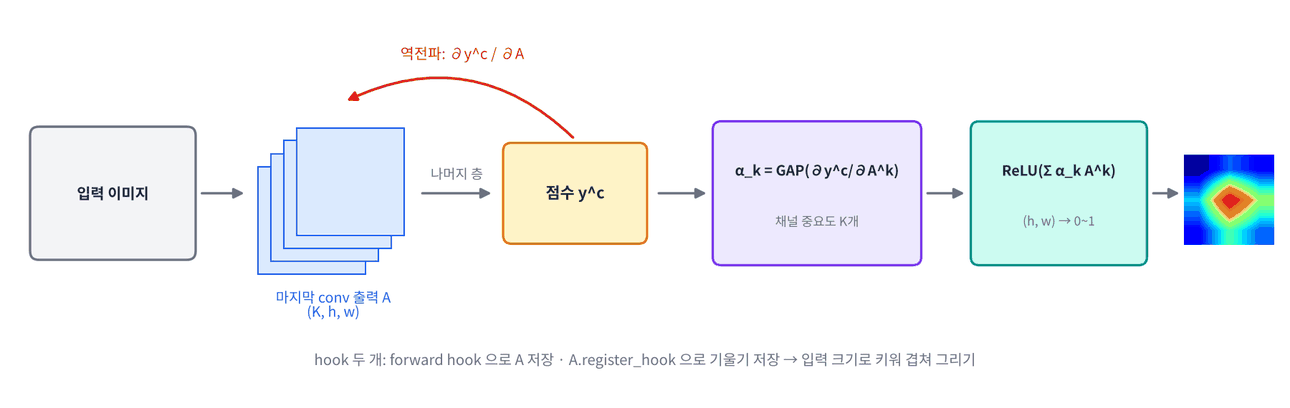

In [ ]:
#@title 🖼 그림 — Grad-CAM 계산 과정
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day3/img/f7_gradcam.png", embed=True, width=860))

**문제 7-1** `GradCAM` 클래스를 완성하세요. forward hook 으로 특징맵을 저장하고, 그 텐서에 `register_hook` 을 걸어 역전파 때 기울기를 받습니다.

In [ ]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        self.handle = layer.register_forward_hook(self._save)

    def _save(self, module, inp, out):
        self.acts = out
        if out.requires_grad:                 # torch.no_grad() 안에서는 건너뜀
            out.register_hook(self._save_grad)

    def _save_grad(self, g):
        self.grads = g

    def __call__(self, x, cls=None):
        self.model.eval()
        logits = self.model(x)
        if cls is None:
            cls = logits.argmax(1)
        self.model.zero_grad()
        logits[torch.arange(len(x)), cls].sum().____
        alpha = self.grads.mean(dim=____, keepdim=True)           # (N, K, 1, 1)
        cam = F.relu((alpha * self.acts).sum(dim=____))                 # (N, H, W)
        cam = cam / (cam.amax(dim=(1, 2), keepdim=True) + 1e-8)
        return cam.detach(), logits.argmax(1).detach()

    def remove(self):
        self.handle.remove()

cam_r20 = GradCAM(r20, r20.layer3)
xb, yb = next(iter(DataLoader(test_cifar, batch_size=16)))
cams, preds = cam_r20(xb.to(device))
print(tuple(cams.shape), "| 예측:", [CLASSES[p][:4] for p in preds[:8].tolist()])

In [ ]:
assert cams.shape == (16, 8, 8) and float(cams.max()) <= 1.0 + 1e-6 and float(cams.min()) >= 0; print("✅")

In [ ]:
#@title 🔒 정답 보기 7-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTEg4pSA4pSACmNsYXNzIEdyYWRDQU06CiAgICBkZWYgX19pbml0X18oc2VsZiwgbW9k"
    "ZWwsIGxheWVyKToKICAgICAgICBzZWxmLm1vZGVsLCBzZWxmLmFjdHMsIHNlbGYuZ3JhZHMgPSBtb2RlbCwgTm9u"
    "ZSwgTm9uZQogICAgICAgIHNlbGYuaGFuZGxlID0gbGF5ZXIucmVnaXN0ZXJfZm9yd2FyZF9ob29rKHNlbGYuX3Nh"
    "dmUpCgogICAgZGVmIF9zYXZlKHNlbGYsIG1vZHVsZSwgaW5wLCBvdXQpOgogICAgICAgIHNlbGYuYWN0cyA9IG91"
    "dAogICAgICAgIGlmIG91dC5yZXF1aXJlc19ncmFkOiAgICAgICAgICAgICAgICAgIyB0b3JjaC5ub19ncmFkKCkg"
    "7JWI7JeQ7ISc64qUIOqxtOuEiOucgAogICAgICAgICAgICBvdXQucmVnaXN0ZXJfaG9vayhzZWxmLl9zYXZlX2dy"
    "YWQpCgogICAgZGVmIF9zYXZlX2dyYWQoc2VsZiwgZyk6CiAgICAgICAgc2VsZi5ncmFkcyA9IGcKCiAgICBkZWYg"
    "X19jYWxsX18oc2VsZiwgeCwgY2xzPU5vbmUpOgogICAgICAgIHNlbGYubW9kZWwuZXZhbCgpCiAgICAgICAgbG9n"
    "aXRzID0gc2VsZi5tb2RlbCh4KQogICAgICAgIGlmIGNscyBpcyBOb25lOgogICAgICAgICAgICBjbHMgPSBsb2dp"
    "dHMuYXJnbWF4KDEpCiAgICAgICAgc2VsZi5tb2RlbC56ZXJvX2dyYWQoKQogICAgICAgIGxvZ2l0c1t0b3JjaC5h"
    "cmFuZ2UobGVuKHgpKSwgY2xzXS5zdW0oKS5iYWNrd2FyZCgpCiAgICAgICAgYWxwaGEgPSBzZWxmLmdyYWRzLm1l"
    "YW4oZGltPSgyLCAzKSwga2VlcGRpbT1UcnVlKSAgICAgICAgICAgIyAoTiwgSywgMSwgMSkKICAgICAgICBjYW0g"
    "PSBGLnJlbHUoKGFscGhhICogc2VsZi5hY3RzKS5zdW0oZGltPTEpKSAgICAgICAgICAgICAgICAgIyAoTiwgSCwg"
    "VykKICAgICAgICBjYW0gPSBjYW0gLyAoY2FtLmFtYXgoZGltPSgxLCAyKSwga2VlcGRpbT1UcnVlKSArIDFlLTgp"
    "CiAgICAgICAgcmV0dXJuIGNhbS5kZXRhY2goKSwgbG9naXRzLmFyZ21heCgxKS5kZXRhY2goKQoKICAgIGRlZiBy"
    "ZW1vdmUoc2VsZik6CiAgICAgICAgc2VsZi5oYW5kbGUucmVtb3ZlKCkKCmNhbV9yMjAgPSBHcmFkQ0FNKHIyMCwg"
    "cjIwLmxheWVyMykKeGIsIHliID0gbmV4dChpdGVyKERhdGFMb2FkZXIodGVzdF9jaWZhciwgYmF0Y2hfc2l6ZT0x"
    "NikpKQpjYW1zLCBwcmVkcyA9IGNhbV9yMjAoeGIudG8oZGV2aWNlKSkKcHJpbnQodHVwbGUoY2Ftcy5zaGFwZSks"
    "ICJ8IOyYiOy4oToiLCBbQ0xBU1NFU1twXVs6NF0gZm9yIHAgaW4gcHJlZHNbOjhdLnRvbGlzdCgpXSkKCvCfkqEg"
    "7ZW07ISkClJlc05ldC0yMCDsnZggbGF5ZXIzIOy2nOugpeydgCAoNjQsIDgsIDgpIOydtOudvCBDQU0g64+EIDjD"
    "lzguIOuNp+yFiO2VnCDrkqQgUmVMVSDrpbwg6rGw64qUIOydtOycoDog6re4IO2BtOuemOyKpCDsoJDsiJjrpbwg"
    "KirsmKzrpqzripQqKiDsnITsuZjrp4wg67O06rOgIOyLtuq4sCDrlYzrrLjsnoXri4jri6Qu"
).decode("utf-8"))

In [ ]:
def show_cams(images, cams, titles, size=32, n=8):
    """images: (N, 3, H, W) 정규화된 텐서 · cams: (N, h, w) — 원본 위에 히트맵을 겹쳐 그린다"""
    up = F.interpolate(cams[:n, None].float().cpu(), size=size, mode="bilinear", align_corners=False)[:, 0]
    fig, ax = plt.subplots(2, n, figsize=(1.7 * n, 3.7))
    for i in range(n):
        ax[0, i].imshow(test_cifar.data[i] if images is None else images[i]); ax[0, i].axis("off"); ax[0, i].set_title(titles[i], fontsize=8)
        ax[1, i].imshow(test_cifar.data[i] if images is None else images[i]); ax[1, i].imshow(up[i], cmap="jet", alpha=0.45); ax[1, i].axis("off")
    plt.tight_layout(); plt.show()

titles = [f"{CLASSES[t][:5]}→{CLASSES[p][:5]}" for t, p in zip(yb[:8].tolist(), preds[:8].tolist())]
show_cams(test_cifar.data[:8], cams, titles)

**문제 7-2** **틀린 이미지**에서 Grad-CAM 을 보세요. 예측한 클래스의 CAM 과 **정답 클래스**의 CAM 을 나란히 그려 무엇에 속았는지 봅니다. `cam(x, cls=...)` 로 원하는 클래스를 지정할 수 있습니다.

In [ ]:
P_r20, Y_r20 = predict_all(r20, test_cifar_loader)
wrong = np.where(P_r20 != Y_r20)[0][:8]
xw = torch.stack([test_cifar[i][0] for i in wrong]).to(device)
cam_pred, _ = cam_r20(xw)
cam_true, _ = cam_r20(xw, cls=torch.tensor(Y_r20[wrong], device=device))

In [ ]:
assert cam_pred.shape == cam_true.shape == (8, 8, 8); print("✅")
up_p = F.interpolate(cam_pred[:, None].cpu(), size=32, mode="bilinear")[:, 0]
up_t = F.interpolate(cam_true[:, None].cpu(), size=32, mode="bilinear")[:, 0]
fig, ax = plt.subplots(3, 8, figsize=(13.5, 5.4))
for j, i in enumerate(wrong):
    for r_, (img_cam, lab) in enumerate([(None, "image"), (up_p[j], f"pred {CLASSES[P_r20[i]][:5]}"), (up_t[j], f"true {CLASSES[Y_r20[i]][:5]}")]):
        ax[r_, j].imshow(test_cifar.data[i]); ax[r_, j].axis("off"); ax[r_, j].set_title(lab, fontsize=8)
        if img_cam is not None: ax[r_, j].imshow(img_cam, cmap="jet", alpha=0.45)
plt.tight_layout(); plt.show()
cam_r20.remove()          # hook 떼기 — 붙여 두면 이후 r20 을 쓸 때마다 실행된다

In [ ]:
#@title 🔒 정답 보기 7-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTIg4pSA4pSAClBfcjIwLCBZX3IyMCA9IHByZWRpY3RfYWxsKHIyMCwgdGVzdF9jaWZh"
    "cl9sb2FkZXIpCndyb25nID0gbnAud2hlcmUoUF9yMjAgIT0gWV9yMjApWzBdWzo4XQp4dyA9IHRvcmNoLnN0YWNr"
    "KFt0ZXN0X2NpZmFyW2ldWzBdIGZvciBpIGluIHdyb25nXSkudG8oZGV2aWNlKQpjYW1fcHJlZCwgXyA9IGNhbV9y"
    "MjAoeHcpCmNhbV90cnVlLCBfID0gY2FtX3IyMCh4dywgY2xzPXRvcmNoLnRlbnNvcihZX3IyMFt3cm9uZ10sIGRl"
    "dmljZT1kZXZpY2UpKQoK8J+SoSDtlbTshKQK7JiI7LihIO2BtOuemOyKpOydmCBDQU0g7J20IOusvOyytOqwgCDs"
    "lYTri4wg67Cw6rK9IMK3IOqwgOyepeyekOumrOyXkCDrqrDroKQg7J6I64uk66m0IOuqqOuNuOydtCDrp6Xrnb3s"
    "l5Ag7IaN7J2AIOqyg+yeheuLiOuLpC4g7J2065+wIOyYpOuLteydtCDrp47snLzrqbQg642w7J207YSw7JeQIOq3"
    "uCDsg4Htmako67Cw6rK9IOuLpOyWke2ZlCkg7J2EIOuNlCDrhKPslrTslbwg7ZWp64uI64ukLg=="
).decode("utf-8"))

**문제 7-3** 5교시 fine-tuning MobileNet(`ft`) 의 Grad-CAM 을 구하세요. 마지막 특징맵 층은 `ft.features[-1]` 입니다. CAM 크기는 몇 × 몇일까요?

In [ ]:
cam_mn = GradCAM(ft, ft.features[____])
xm = torch.stack([test_mn[i][0] for i in range(8)]).to(device)
cams_mn, preds_mn = cam_mn(xm)
print("MobileNet CAM:", tuple(cams_mn.shape))

In [ ]:
assert cams_mn.shape == (8, 3, 3); print("✅")
show_cams(test_cifar.data[:8], cams_mn, [f"{CLASSES[test_mn[i][1]][:5]}→{CLASSES[p][:5]}" for i, p in enumerate(preds_mn.tolist())])
cam_mn.remove()

In [ ]:
#@title 🔒 정답 보기 7-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTMg4pSA4pSACmNhbV9tbiA9IEdyYWRDQU0oZnQsIGZ0LmZlYXR1cmVzWy0xXSkKeG0g"
    "PSB0b3JjaC5zdGFjayhbdGVzdF9tbltpXVswXSBmb3IgaSBpbiByYW5nZSg4KV0pLnRvKGRldmljZSkKY2Ftc19t"
    "biwgcHJlZHNfbW4gPSBjYW1fbW4oeG0pCnByaW50KCJNb2JpbGVOZXQgQ0FNOiIsIHR1cGxlKGNhbXNfbW4uc2hh"
    "cGUpKQoK8J+SoSDtlbTshKQKOTbDlzk2IOyeheugpeydtCBzdHJpZGUgMzIg66W8IOqxsOyzkCAzw5czLiDqsr3r"
    "n4kg66qo64247J2AIOu5qOumrCDspITsl6zshJwg7Jew7IKw7J2EIOyVhOuBvOuvgOuhnCBDQU0g7J20IOqxsOy5"
    "qeuLiOuLpCDigJQgUmVzTmV0LTIwIChzdHJpZGUgNCwgOMOXOCkg6rO87J2YIOywqOydtC4g7JyE7LmY66W8IOyg"
    "leuwgO2VmOqyjCDslYzslYTslbwg7ZWY66m0IOu2hOulmOqwgCDslYTri4jrnbwgKirqsJ3ssrQg7YOQ7KeAKiog"
    "KERheSA0KSDqsIAg7ZWE7JqU7ZWp64uI64ukLg=="
).decode("utf-8"))

#### 📌 7교시 정리

- Grad-CAM: 마지막 합성곱 출력 A, 기울기의 공간 평균 α, ReLU(Σ αA) → 정규화 → 겹쳐 그리기.
- 오답에서 예측 · 정답 클래스의 CAM 을 비교하면 무엇에 속았는지 보인다.
- CAM 해상도 = 마지막 특징맵 크기 (ResNet-20 8×8, MobileNetV3 96 입력 3×3).

## 8교시 — 미니 프로젝트: MobileNetV3 전이학습 vs ResNet-20

사전학습 MobileNetV3-Small 을 CIFAR-10 전체로 fine-tuning 해서 Day 2 의 ResNet-20 (처음부터 20 epoch, test 약 0.86) 과 비교합니다. 정확도만이 아니라 **연산량 · 지연시간까지** 보고 장치에 올릴 모델을 고르는 것이 목표입니다.

| 과제 | 내용 | 배점 |
|---|---|---|
| 1 | 증강 로더 · 사전학습 모델 준비 · AdamW + OneCycleLR | 20 |
| 2 | fine-tuning 5 epoch — **test ≥ 0.85** | 30 |
| 3 | 비교표 — 파라미터 · MAC · CPU 지연시간 · test 정확도 | 20 |
| 4 | 오답 8장 Grad-CAM | 10 |
| 5 | 결과 해석 (마크다운) | 10 + 10 (강사) |

학습 시간: T4 GPU 로 epoch 당 약 1분 (예상). 강사 사전 실행 예: 5 epoch test 0.8842.

> 🎬 **애니메이션** [D3-8 모델 고르기 — 비교표](https://imguru-mooc.github.io/AI_CAMPUS/VB-day3/animation.html#d3-8)
> 📝 **워크시트** [8교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day3/worksheet.html#t8)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

### 과제 1 — 준비 (20점)

- train 로더: `train_mn` (증강 + Resize 96 + ImageNet 정규화), 배치 128, 섞기
- 모델: 사전학습 MobileNetV3-Small, `classifier[3]` → 10 클래스
- 옵티마이저: **AdamW** (lr 1e-3, weight_decay 1e-4), 스케줄러: OneCycleLR (max_lr 1e-3, `EPOCHS`, steps_per_epoch = 로더 길이)

In [ ]:
EPOCHS = 5
mn_loader = DataLoader(train_mn, batch_size=128, shuffle=True, num_workers=NW, pin_memory=True)
torch.manual_seed(0)
model = torchvision.models.mobilenet_v3_small(weights=W_MNV3S)
model.classifier[3] = nn.Linear(1024, ____)
model = model.to(device)
opt = torch.optim.____(model.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=1e-3, epochs=EPOCHS, steps_per_epoch=____)
print("step / epoch:", len(mn_loader))

In [ ]:
#@title 🔒 정답 보기 8-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTEg4pSA4pSACkVQT0NIUyA9IDUKbW5fbG9hZGVyID0gRGF0YUxvYWRlcih0cmFpbl9t"
    "biwgYmF0Y2hfc2l6ZT0xMjgsIHNodWZmbGU9VHJ1ZSwgbnVtX3dvcmtlcnM9TlcsIHBpbl9tZW1vcnk9VHJ1ZSkK"
    "dG9yY2gubWFudWFsX3NlZWQoMCkKbW9kZWwgPSB0b3JjaHZpc2lvbi5tb2RlbHMubW9iaWxlbmV0X3YzX3NtYWxs"
    "KHdlaWdodHM9V19NTlYzUykKbW9kZWwuY2xhc3NpZmllclszXSA9IG5uLkxpbmVhcigxMDI0LCAxMCkKbW9kZWwg"
    "PSBtb2RlbC50byhkZXZpY2UpCm9wdCA9IHRvcmNoLm9wdGltLkFkYW1XKG1vZGVsLnBhcmFtZXRlcnMoKSwgbHI9"
    "MWUtMywgd2VpZ2h0X2RlY2F5PTFlLTQpCnNjaGVkID0gdG9yY2gub3B0aW0ubHJfc2NoZWR1bGVyLk9uZUN5Y2xl"
    "TFIob3B0LCBtYXhfbHI9MWUtMywgZXBvY2hzPUVQT0NIUywgc3RlcHNfcGVyX2Vwb2NoPWxlbihtbl9sb2FkZXIp"
    "KQ=="
).decode("utf-8"))

### 과제 2 — fine-tuning (30점)

In [ ]:
t_start = time.perf_counter()
hist_mn = fit(model, ____, test_mn_loader, EPOCHS, opt, ____, label="MobileNetV3-S")
train_min = (time.perf_counter() - t_start) / 60
mn_acc = hist_mn["test_acc"][-1]
torch.save(model.state_dict(), "mnv3s_cifar10.pt")
print(f"test {mn_acc:.4f} | 학습 {train_min:.1f} 분")

In [ ]:
#@title 🔒 정답 보기 8-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTIg4pSA4pSACnRfc3RhcnQgPSB0aW1lLnBlcmZfY291bnRlcigpCmhpc3RfbW4gPSBm"
    "aXQobW9kZWwsIG1uX2xvYWRlciwgdGVzdF9tbl9sb2FkZXIsIEVQT0NIUywgb3B0LCBzY2hlZCwgbGFiZWw9Ik1v"
    "YmlsZU5ldFYzLVMiKQp0cmFpbl9taW4gPSAodGltZS5wZXJmX2NvdW50ZXIoKSAtIHRfc3RhcnQpIC8gNjAKbW5f"
    "YWNjID0gaGlzdF9tblsidGVzdF9hY2MiXVstMV0KdG9yY2guc2F2ZShtb2RlbC5zdGF0ZV9kaWN0KCksICJtbnYz"
    "c19jaWZhcjEwLnB0Iik="
).decode("utf-8"))

### 과제 3 — 비교표 (20점)

두 모델을 **각자의 입력 크기**로 잽니다 (ResNet-20: 32×32, MobileNetV3-S: 96×96). `compare` 딕셔너리에 (파라미터, MAC, 지연시간 ms, test 정확도) 를 넣으세요.

In [ ]:
compare = {
    "ResNet-20 (scratch, 32)": (count_params(r20), count_macs(r20, (1, 3, 32, 32)), latency_ms(r20, (1, 3, 32, 32)), acc_r20),
    "MobileNetV3-S (transfer, 96)": (count_params(model), count_macs(model, (____)),
                                     latency_ms(model, (1, 3, IMG, IMG)), ____),
}
print(f"{'모델':30s} {'파라미터':>10s} {'MAC':>12s} {'지연시간':>9s} {'test':>7s}")
for k, (p, m, t, a) in compare.items():
    print(f"{k:30s} {p:>10,} {m:>12,} {t:7.2f}ms {a:7.4f}")

In [ ]:
#@title 🔒 정답 보기 8-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTMg4pSA4pSACmNvbXBhcmUgPSB7CiAgICAiUmVzTmV0LTIwIChzY3JhdGNoLCAzMiki"
    "OiAoY291bnRfcGFyYW1zKHIyMCksIGNvdW50X21hY3MocjIwLCAoMSwgMywgMzIsIDMyKSksIGxhdGVuY3lfbXMo"
    "cjIwLCAoMSwgMywgMzIsIDMyKSksIGFjY19yMjApLAogICAgIk1vYmlsZU5ldFYzLVMgKHRyYW5zZmVyLCA5Niki"
    "OiAoY291bnRfcGFyYW1zKG1vZGVsKSwgY291bnRfbWFjcyhtb2RlbCwgKDEsIDMsIElNRywgSU1HKSksCiAgICAg"
    "ICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICBsYXRlbmN5X21zKG1vZGVsLCAoMSwgMywgSU1HLCBJTUcp"
    "KSwgbW5fYWNjKSwKfQoK8J+SoSDtlbTshKQK7Iuk7ZaJIOyYiDogUmVzTmV0LTIwIDI3Miw0NzQg7YyM652866+4"
    "7YSwIMK3IDQwLDgxMywxODQgTUFDIMK3IDIuODcgbXMgwrcgMC44NTg3IC8gTW9iaWxlTmV0VjMtUyAxLDUyOCwx"
    "MDYgwrcgMTEsMDU3LDYwMCDCtyA2LjE4IG1zIMK3IDAuODg0Mi4="
).decode("utf-8"))

### 과제 4 — 오답 Grad-CAM (10점)

MobileNet 이 틀린 test 이미지 8장의 Grad-CAM (예측 클래스) 을 그리세요. `wrong_mn` 에 오답 인덱스 8개, `cams_wrong` 에 (8, 3, 3) CAM.

In [ ]:
P_mn, Y_mn = predict_all(model, test_mn_loader)
wrong_mn = np.where(P_mn ____ Y_mn)[0][:8]
cam_m = GradCAM(model, model.features[-1])
cams_wrong, _ = cam_m(torch.stack([test_mn[i][0] for i in wrong_mn]).to(device))
cam_m.remove()
show_cams(test_cifar.data[wrong_mn], cams_wrong, [f"{CLASSES[Y_mn[i]][:5]}→{CLASSES[P_mn[i]][:5]}" for i in wrong_mn])

In [ ]:
#@title 🔒 정답 보기 8-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTQg4pSA4pSAClBfbW4sIFlfbW4gPSBwcmVkaWN0X2FsbChtb2RlbCwgdGVzdF9tbl9s"
    "b2FkZXIpCndyb25nX21uID0gbnAud2hlcmUoUF9tbiAhPSBZX21uKVswXVs6OF0KY2FtX20gPSBHcmFkQ0FNKG1v"
    "ZGVsLCBtb2RlbC5mZWF0dXJlc1stMV0pCmNhbXNfd3JvbmcsIF8gPSBjYW1fbSh0b3JjaC5zdGFjayhbdGVzdF9t"
    "bltpXVswXSBmb3IgaSBpbiB3cm9uZ19tbl0pLnRvKGRldmljZSkpCmNhbV9tLnJlbW92ZSgp"
).decode("utf-8"))

### 과제 5 — 결과 해석 (10점 + 강사 10점)

1. 두 모델 중 **라즈베리파이에 올릴 모델**을 하나 고르고, 비교표의 숫자로 근거를 대세요.
2. MobileNetV3 는 파라미터가 ResNet-20 의 5.6배인데 MAC 은 약 1/3.7 이다. 어떻게 가능한가?
3. 같은 MobileNetV3 를 224×224 로 넣으면 정확도 · 지연시간이 어떻게 바뀔까? (입력 크기와 MAC 의 관계)
4. 현장 안전 데이터(클래스당 수백 장) 라면 오늘 실험 중 어떤 결과를 근거로 어떤 방법을 쓰겠나?

✍️ *여기에 답을 쓰세요.*

In [ ]:
#@title 🔒 해설 보기 8교시 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIO2VtOyEpCDilIDilIAKMS4g7Iuk7ZaJIOyYiOyXkOyEnCBNb2JpbGVOZXRWMy1TICjsoITsnbTtlZns"
    "irUpIOuKlCDsoJXtmZXrj4QgMC44ODQyIOuhnCBSZXNOZXQtMjAgKDAuODU4Nykg7JmAIOu5hOyKt+2VmOqxsOuC"
    "mCDrhpLqs6AsIE1BQyDsnYAg7JW9IDEvMy43ICgxMSwwNTcsNjAwIHZzIDQwLDgxMywxODQpLiDqt7jrn7DrjbAg"
    "7Iuk7ZaJIOyYiOydmCBDUFUg7KeA7Jew7Iuc6rCE7J2AIOyYpO2eiOugpCBNb2JpbGVOZXQg7J20IOuNlCDquYHr"
    "i4jri6QgKDYuMTggbXMgdnMgMi44NyBtcykg4oCUIOyeheugpeydtCA5NsOXOTYg66GcIDnrsLAg7YGs6rOgLCBk"
    "ZXB0aHdpc2UgwrcgU0Ugwrcg7Li1IOyImOqwgCDrp47slYQg66mU66qo66asIOydtOuPmeqzvCDtmLjstpwg7Jik"
    "67KE7Zek65Oc6rCAIO2BrOq4sCDrlYzrrLjsnoXri4jri6QgKDPqtZDsi5zsmYAg6rCZ7J2AIOydtOyVvOq4sCku"
    "IE1BQyDsnbQg7KCB64uk6rOgIOu5oOuluCDqsoPsnbQg7JWE64uI66+A66GcIOyLpOygnCDsnqXsuZjsl5DshJwg"
    "7J6s7IScIOqysOyglSDigJQgRGF5IDUgwrcgT05OWMK3VGVuc29yUlQuIOygle2ZleuPhOqwgCDspJHsmpTtlZjr"
    "qbQgTW9iaWxlTmV0LCBDUFUg7KeA7Jew7Iuc6rCE7J20IOqwgOyepSDspJHsmpTtlZjrqbQgUmVzTmV0LTIwIOuP"
    "hCDsoovsnYAg7ISg7YOd7J6F64uI64ukLgoyLiDtjIzrnbzrr7jthLDsnZgg64yA67aA67aEKDYwMSwwOTggKyBm"
    "ZWF0dXJlcyDsnZggMcOXMSDsuLXrk6QpIOydgCAn7JyE7LmY66eI64ukIO2VnCDrsognIOyTsOydtOuKlCAxw5cx"
    "IMK3IEZDIOyXkCDsnojqs6AsIDk2IOyeheugpeydtCDruaDrpbTqsowg7KSE7Ja0KHN0cmlkZSAyIOulvCDsnbzs"
    "sI0pIO2BsCDtirnsp5Xrp7Xsl5DshJwg7ZWY64qUIOyXsOyCsOydtCDsoIHri6QuIFJlc05ldC0yMCDsnYAgMzLD"
    "lzMyIO2VtOyDgeuPhOulvCDsnKDsp4DtlZwg7LGEIDPDlzMg7J2EIOyXrOufrCDrsogg7ZW07IScIO2MjOudvOuv"
    "uO2EsOuKlCDsoIHslrTrj4QgTUFDIOydtCDtgazri6QuCjMuIE1BQyDsnYAg7ZW07IOB64+E7J2YIOygnOqzseyX"
    "kCDruYTroYAg4oCUIDk2IOKGkiAyMjQg66m0IOyVvSAoMjI0Lzk2KcKyIOKJiCA1LjTrsLAgKDEyLjFNIOKGkiA1"
    "Ni41TSwgMTAwMCDtgbTrnpjsiqQg6riw7KSAKS4g7KCV7ZmV64+E64qUIOyYpOultOyngOunjCAzMsOXMzIg7JuQ"
    "67O47J2EIO2BrOqyjCDtgqTsmrQg6rKD7J206528IOydtOuTneydtCDsoJztlZzsoIHsnbTri6QuCjQuIDbqtZDs"
    "i5wgKDEsMDAw7J6l7JeQ7IScIOyymOydjOu2gO2EsCAwLjM1NjAgdnMg7IKs7KCE7ZWZ7Iq1IDAuNjU2MSkg4oaS"
    "IOyCrOyghO2VmeyKtSDqsr3rn4kg66qo6424IGZpbmUtdHVuaW5nICsg7Kad6rCVLCBHcmFkLUNBTSDsnLzroZwg"
    "7JWI7KCE66qo66W8IOuztOuKlOyngCDtmZXsnbgu"
).decode("utf-8"))

### 채점 셀

In [ ]:
score = 0
try:
    assert isinstance(opt, torch.optim.AdamW) and isinstance(sched, torch.optim.lr_scheduler.OneCycleLR)
    assert model.classifier[3].out_features == 10 and len(mn_loader) == 391
    score += 20; print("✅ 과제 1  +20")
except Exception as e: print("❌ 과제 1", e)
try:
    assert len(hist_mn["test_acc"]) == EPOCHS and mn_acc >= 0.85
    score += 30; print(f"✅ 과제 2  +30  (test {mn_acc:.4f}, {train_min:.1f} 분)")
except Exception as e: print("❌ 과제 2", e)
try:
    assert len(compare) == 2 and all(len(v) == 4 for v in compare.values())
    assert compare["MobileNetV3-S (transfer, 96)"][1] == 11_057_600 and compare["ResNet-20 (scratch, 32)"][1] == 40_813_184
    score += 20; print("✅ 과제 3  +20")
except Exception as e: print("❌ 과제 3", e)
try:
    assert len(wrong_mn) == 8 and cams_wrong.shape == (8, 3, 3) and (P_mn[wrong_mn] != Y_mn[wrong_mn]).all()
    score += 10; print("✅ 과제 4  +10")
except Exception as e: print("❌ 과제 4", e)
print(f"\n자동 채점 {score} / 80  (과제 5 해석은 강사 채점 20점)")

### 🔎 더 알아보기

과제 5 를 제출한 뒤에 보세요. 오늘의 MobileNetV3 는 float32 · PyTorch 그대로입니다. 장치에서는 여기서 두 단계가 더 있습니다 — **ONNX 로 내보내 TensorRT 엔진**으로 바꾸기 (11/4~), **int8 양자화 · 가지치기** (11/16~). 그리고 '어디에 있는가' 까지 알아야 하는 현장 안전에는 다음 시간의 **객체 탐지**가 필요합니다.

#### 📌 8교시 정리

- 사전학습 경량 모델 + fine-tuning 은 처음부터 학습한 모델과 비슷하거나 높은 정확도를 훨씬 적은 MAC 으로 낸다.
- 모델 선택은 정확도 · 파라미터 · MAC · 실제 지연시간을 함께.
- Grad-CAM 으로 근거를 확인한다 — 경량 모델은 CAM 이 거칠다.

## 오늘의 정리

### 셀프 체크

- [ ] 온디바이스 조건(CPU · 스레드 1 · 배치 1 · warm-up) 으로 지연시간을 잴 수 있다
- [ ] 파라미터 메모리 · 활성화 메모리 · MAC 의 차이를 설명할 수 있다
- [ ] 1×1 bottleneck 과 Depthwise Separable 이 연산을 줄이는 원리를 공식으로 말할 수 있다
- [ ] MobileNet V1 · V2 · V3 의 핵심 아이디어를 하나씩 말할 수 있다
- [ ] 사전학습 모델의 분류기를 바꾸고 feature extraction · fine-tuning 을 할 수 있다
- [ ] 데이터가 적을 때 전이학습이 왜 중요한지 실험 결과로 설명할 수 있다
- [ ] Grad-CAM 의 계산 단계를 설명하고 hook 으로 구현할 수 있다

### 다음 시간 (Day 4 · 11/2 월) 예고

분류기는 '무엇이' 만 답합니다. **'무엇이 어디에'** — bbox · IoU · NMS · mAP 를 NumPy 로 직접 구현하고, 사전학습 탐지기로 영상 속 사람을 찾고 셉니다.